# 202_04 — Evaluación predictiva · Escenario TAR · **barrido en $M$**

Paso **3b** del ciclo. Supone que `202_03_convergencia` dio veredicto OK **en
cada punto del barrido**; si las cadenas de un $M$ no convergieron, sus cifras
aquí no significan nada.

## Qué se reporta

- Predicción funcional a $h=1$ y su intervalo de credibilidad — se PERSISTEN, es lo que consume `202_05`
- **Bloque A** (MAE, RMSE, error máximo) sobre la ventana móvil
- **Bloque B** (Winkler, cobertura simultánea, cobertura puntual, MPIW) sobre la ventana móvil
- Muestra de predicciones: extractos regulares del test y las peores ventanas, con la curva anterior al lado
- Probabilidades posteriores de inclusión (PIP) contra la estructura del generador
- Cuadro resumen: mínimo, máximo y promedio de cada métrica sobre la ventana
- Monitoreo univariado por componente FPCA
- **§10: evaluación puntual de los scores (coeficientes)** — banda de credibilidad de cada $\xi_k$, métricas de intervalo sobre ella, y dispersión $\hat\xi$ contra $\xi$

Todo el cálculo vive en `fit/` y todo el dibujo en `graphics/`: este notebook
sólo orquesta.



## 1. Imports, `[CONFIG]` y artefactos

In [1]:
import sys

import numpy as np
import matplotlib.pyplot as plt

from model_psbp_fd.fit.convergencia_barrido import (
    cargar_artefactos, cargar_trazas, pip_punto, contraste_generador,
)
from model_psbp_fd.fit.evaluacion_barrido import (
    METRICAS_A as _MA, METRICAS_B as _MB,
    cargar_representaciones, serie_origenes, predecir_barrido, guardar_bandas,
    tablas_ventana, apilar_tablas, verificar_relaciones_metricas,
    ganancias_por_ventana, tabla_ganadores_test, saltos_T0, peores_ventanas,
    resumen_metricas, resumen_barrido, monitoreo_scores, intervalos_scores,
)
from model_psbp_fd.graphics import (
    plot_ventana_movil, plot_extractos_curvas,
    plot_ganador_ventana, plot_scores_banda, plot_scores_dispersion,
)
from model_psbp_fd.utils import get_project_root, experiment_id, normalizar_lista_M
from model_psbp_fd.utils.rutas import ruta_barrido_M

plt.style.use("seaborn-v0_8-darkgrid")
%matplotlib inline

### 1.1 `[CONFIG]` Identificación del experimento y barrido en $M$

In [2]:
PROJECT_ROOT = get_project_root()
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Mismos valores que 202_01 §1.1.
VARIANTE     = "chungEscX"
BASENAME     = f"escenario_202_{VARIANTE}"
ESCENARIO_ID = 1      # escenario TAR (único)
REPLICA_ID   = 1      # réplica Monte Carlo
M_FPCA_LIST  = (3, 4, 5, 6)

# Propias de la evaluación. Las ventanas, el nivel y el objetivo se LEEN de
# eval_config.json (artefacto de 202_01): no se redeclaran aquí.
SALTAR_M_SIN_TRAZAS = True    # mirar el barrido mientras MATLAB va terminando
PESOS_TAU           = None    # cuadratura trapezoidal por defecto
METRICA_PEORES      = "rmse_f"   # cualquiera de las columnas de METRICAS_A / METRICAS_B
N_PEORES            = 5

# Predicción a h=1 (§3). S = (nsim - burn) x S_POR_ITER x n_cadenas draws por score;
# subirlos sólo reduce el error Monte Carlo de los cuantiles.
S_POR_ITER  = 1
S_FUNC      = 1000      # muestras funcionales tras adelgazar
BLOQUE_ORIG = 200       # orígenes por tramo al propagar a la curva (memoria)
SEED_PRED   = 20260823
CADA        = 30        # un extracto de curva cada CADA períodos (§6)
CADA_BARRA  = 12        # un origen de cada CADA_BARRA lleva barra de IC (§10.3)

# §7: contraste de PIP con el generador.
UMBRAL_PIP = 0.5
SD_PIP_MAX = 0.15
COS_MIN    = 0.95

# Las 10 métricas del marco teórico 02_02_03, en su orden. No se agregan otras.
METRICAS_A = [("1. MAE  (L^1)", "mae_f"), ("2. RMSE (L^2)", "rmse_f"),
              ("3. E_max promedio por curva", "linf_medio"),
              ("4. E_max peor de la ventana", "linf_max")]
METRICAS_B = [("5. MPIW", "mpiw"), ("6. PICP puntual", "picp"),
              ("7. PICPB curva completa", "picp_simultaneo"), ("8. Winkler", "winkler"),
              ("9. Winkler max promedio", "winkler_max_medio"),
              ("10. Winkler max peor ventana", "winkler_max_glob")]
assert METRICAS_A == _MA and METRICAS_B == _MB, "METRICAS_* difieren de fit.evaluacion_barrido."
METRICAS_A_COLS = [c for _, c in METRICAS_A]
METRICAS_B_COLS = [c for _, c in METRICAS_B]

M_FPCA_LIST     = normalizar_lista_M(M_FPCA_LIST)
EXPERIMENT_BASE = experiment_id(BASENAME, ESCENARIO_ID, REPLICA_ID)
PATH_BARRIDO    = ruta_barrido_M(BASENAME, ESCENARIO_ID, REPLICA_ID, project_root=PROJECT_ROOT)

print(f"EXPERIMENT_BASE : {EXPERIMENT_BASE}")
print(f"barrido en M    : {list(M_FPCA_LIST)}")
print(f"salidas cruzadas: {PATH_BARRIDO}")

EXPERIMENT_BASE : escenario_202_chungEscX_1_r01
barrido en M    : [3, 4, 5, 6]
salidas cruzadas: C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_barrido_M


In [3]:
# EST[M]: estado de cada punto (cruza el contrato al cargar). DIS: diseño común.
EST, saltados = cargar_artefactos(BASENAME, ESCENARIO_ID, REPLICA_ID, M_FPCA_LIST,
                                  PROJECT_ROOT, con_test=True)
DIS = cargar_representaciones(EST)

T, T0, N_LAGS, NIVEL = DIS["T"], DIS["T0"], DIS["N_LAGS"], DIS["NIVEL"]
VENTANAS_W, W_REF    = DIS["VENTANAS_W"], DIS["W_REF"]
grilla, X_true, X_obs, X_suav = DIS["grilla"], DIS["X_true"], DIS["X_obs"], DIS["X_suav"]

  M  comp  cadenas  covariables  seed_base
  3     3        3            6  41232
  4     4        3            8  41232
  5     5        3           10  41232
  6     6        3           12  41232

OK misma configuracion MCMC en todos los M: nsim/N/burn/cadenas = (2500, 30, 500, 3)
M=3  FPCA M=3 K=10  var. explicada=85.2356%  ·  curvas (1000, 75)
M=4  FPCA M=4 K=10  var. explicada=91.5213%  ·  curvas (1000, 75)
M=5  FPCA M=5 K=10  var. explicada=95.5660%  ·  curvas (1000, 75)
M=6  FPCA M=6 K=10  var. explicada=97.6776%  ·  curvas (1000, 75)

OK 4 puntos con el mismo diseno, objetivo, MCMC y simulacion.
T=1000 T0=700 n_lags=2   ventanas w=[20, 30, 40]   referencia w=30   nivel=0.95


## 2. Trazas MCMC

Una lectura por punto del barrido. El `feature_names` del `.mat` se verifica
contra las columnas del dataset: con $M$ distintos el número de covariables
cambia, y un `.mat` del punto equivocado se detectaría aquí y no más adelante
como un resultado raro.

In [4]:
M_OK = cargar_trazas(EST, SALTAR_M_SIN_TRAZAS)     # los M efectivamente disponibles

OK M=3: 3 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=4: 4 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=5: 5 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente
OK M=6: 6 componente(s) x 3 cadena(s) · 2000 draws posteriores c/u -> 6000 por componente


## 3. Predicción a $h=1$ sobre la serie completa


In [5]:
ORIG = serie_origenes(DIS)
t_orig, n_orig, T0_orig, es_train = ORIG["t_orig"], ORIG["n_orig"], ORIG["T0_orig"], ORIG["es_train"]
X_obj_ev, X_obs_ev = ORIG["X_obj_ev"], ORIG["X_obs_ev"]

predecir_barrido(EST, M_OK, DIS, ORIG, S_POR_ITER, S_FUNC, BLOQUE_ORIG, SEED_PRED)

origenes evaluados: 998  (train 698 · test 300)
SC_draws de TODO el barrido: 431 MB en float32
M=3: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 72 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.174800   <- distancia del objetivo a su propia proyeccion en M
M=4: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 96 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.098823   <- distancia del objetivo a su propia proyeccion en M
M=5: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 120 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.049905   <- distancia del objetivo a su propia proyeccion en M
M=6: S=6000 extracciones por score · funcionales 1000 (1 de cada 6) · SC_draws 144 MB
       MISE del TRUNCAMIENTO FPCA (test) = 0.026036   <- distancia del objetivo a su propia proyeccion en M


### 3.1 Persistencia

La banda y la predicción puntual se guardan en `predict/` -no en `reports/`,
es un objeto de datos y no una salida de lectura- porque `202_05` las necesita
para calcular el Winkler del PSBPM-FD sobre su propia ventana móvil sin volver
a muestrear la predictiva completa.

In [6]:
guardar_bandas(EST, M_OK, DIS, ORIG)

[M=3] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (998, 75))
[M=4] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (998, 75))
[M=5] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (998, 75))
[M=6] banda funcional -> banda_funcional_psbp.npz  (0.8 MB, (998, 75))
Banda por CUANTILES de la predictiva muestral: no supone forma alguna.


## 4. Bloque A: error puntual sobre la ventana móvil

Las tres normas del MISMO error $e_t(\tau) = X_t(\tau) - \hat X_t(\tau)$:

| | qué estima | qué añade |
|---|---|---|
| **MAE** ($L^1$) | mediana condicional | robusta: un origen catastrófico no la mueve |
| **RMSE** ($L^2$) | media condicional | la que usa el PSBPM-FD y el resto del capítulo |
| **Error máximo** ($L^\infty$, promedio por curva) | peor caso | por curva, $\max_\tau \lvert e_t(\tau)\rvert$; sobre la ventana, el promedio de esos $w$ máximos |

Todo se calcula UNA vez por M en `tablas_fun` -la misma tabla que consume el
Bloque B de §5- y se dibuja aquí SOLO el Bloque A.

[ventana_movil_funcional[w=30]] inicio (969 pasos)
  1/969 ( 0.1%) t=0.0s eta=1.3s  t=17 [train] mise=0.6178
  48/969 ( 5.0%) t=0.0s eta=0.2s  t=64 [train] mise=0.7085
  96/969 ( 9.9%) t=0.0s eta=0.1s  t=112 [train] mise=0.8657
  144/969 (14.9%) t=0.0s eta=0.1s  t=160 [train] mise=0.7645
  192/969 (19.8%) t=0.0s eta=0.1s  t=208 [train] mise=0.6789
  240/969 (24.8%) t=0.0s eta=0.1s  t=256 [train] mise=0.6866
  288/969 (29.7%) t=0.0s eta=0.1s  t=304 [train] mise=0.6478
  336/969 (34.7%) t=0.1s eta=0.1s  t=352 [train] mise=0.7796
  384/969 (39.6%) t=0.1s eta=0.1s  t=400 [train] mise=0.6293
  432/969 (44.6%) t=0.1s eta=0.1s  t=448 [train] mise=0.6738
  480/969 (49.5%) t=0.1s eta=0.1s  t=496 [train] mise=0.7309
  528/969 (54.5%) t=0.1s eta=0.1s  t=544 [train] mise=0.8781
  576/969 (59.4%) t=0.1s eta=0.1s  t=592 [train] mise=0.7187
  624/969 (64.4%) t=0.1s eta=0.1s  t=640 [train] mise=0.5556
  672/969 (69.3%) t=0.1s eta=0.0s  t=688 [train] mise=0.6832
  720/969 (74.3%) t=0.1s eta=0.0s  t=736

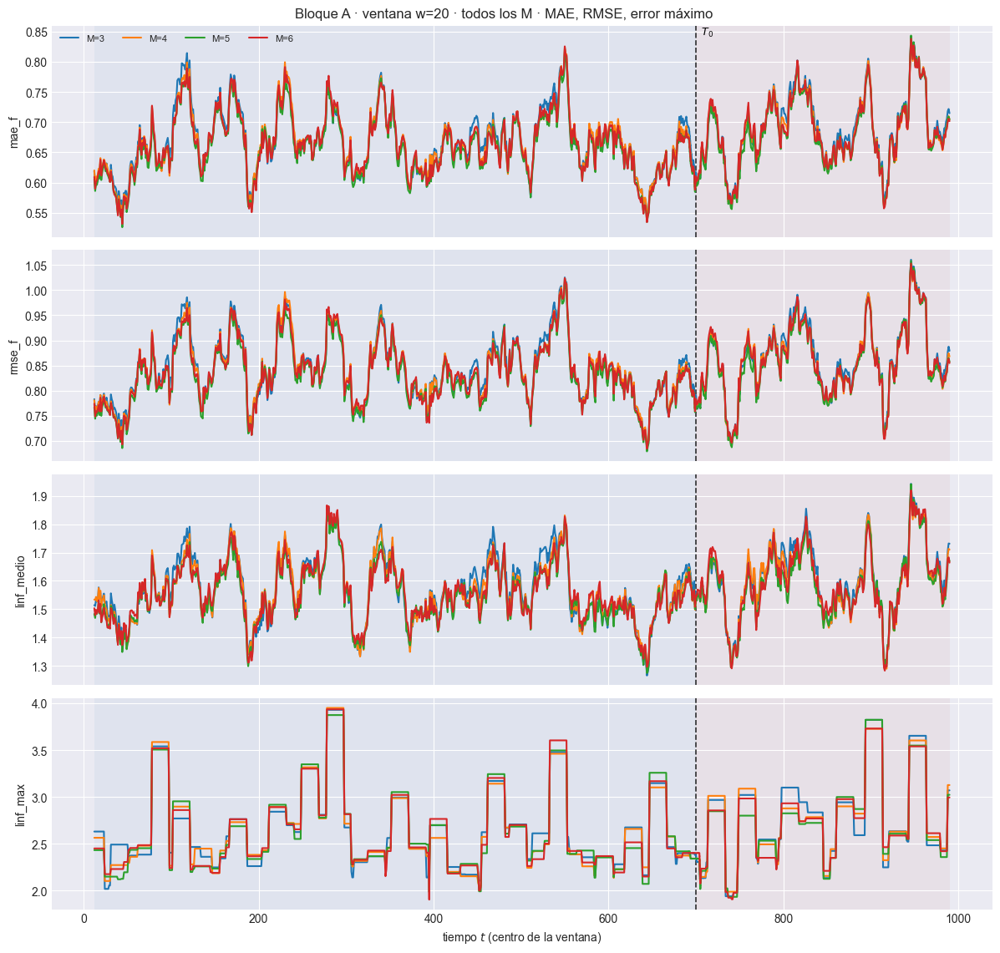

[plot_ventana_movil] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.1s  mae_f: w=30 train=0.6644  w=30 test=0.6852
  2/4 (50.0%) t=0.0s eta=0.0s  rmse_f: w=30 train=0.8376  w=30 test=0.8561
  3/4 (75.0%) t=0.1s eta=0.0s  linf_medio: w=30 train=1.554  w=30 test=1.599
  4/4 (100.0%) t=0.1s eta=0.0s  linf_max: w=30 train=2.693  w=30 test=2.933
[plot_ventana_movil] listo: 4 pasos en 0.5s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_barrido_M\85_bloqueA_w30.png


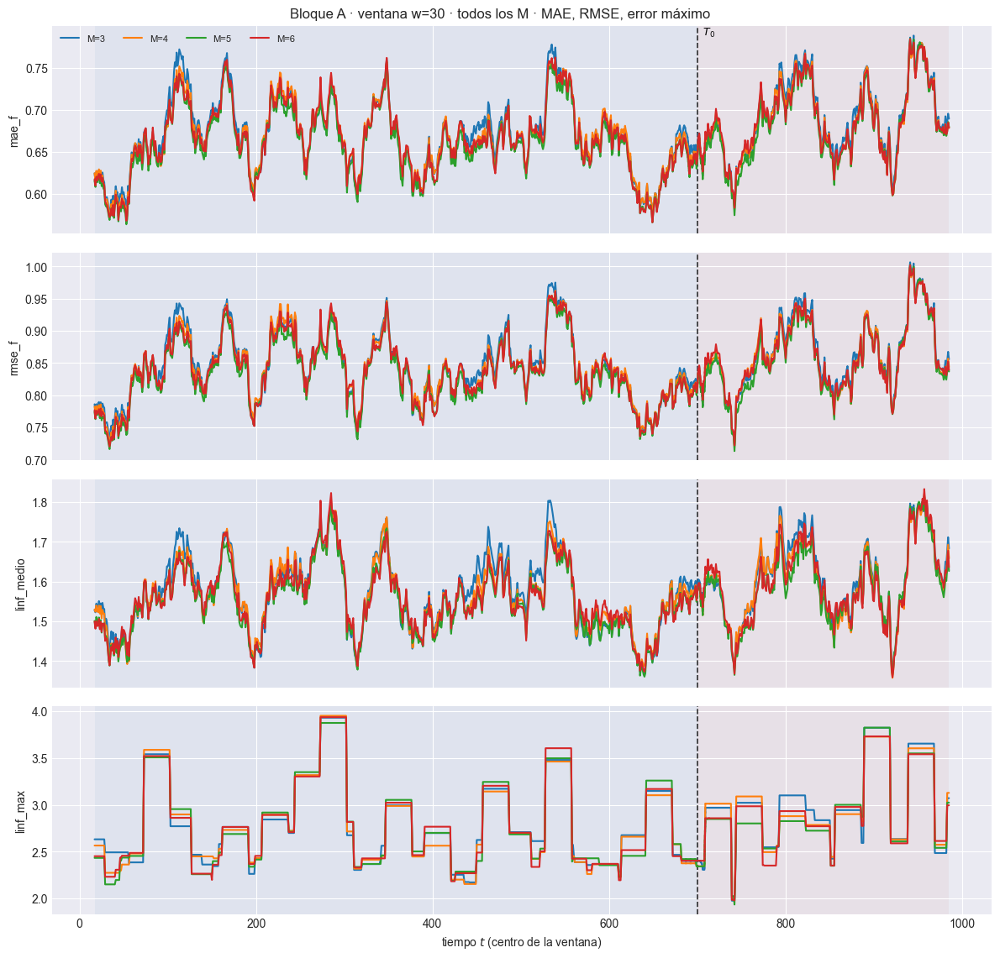

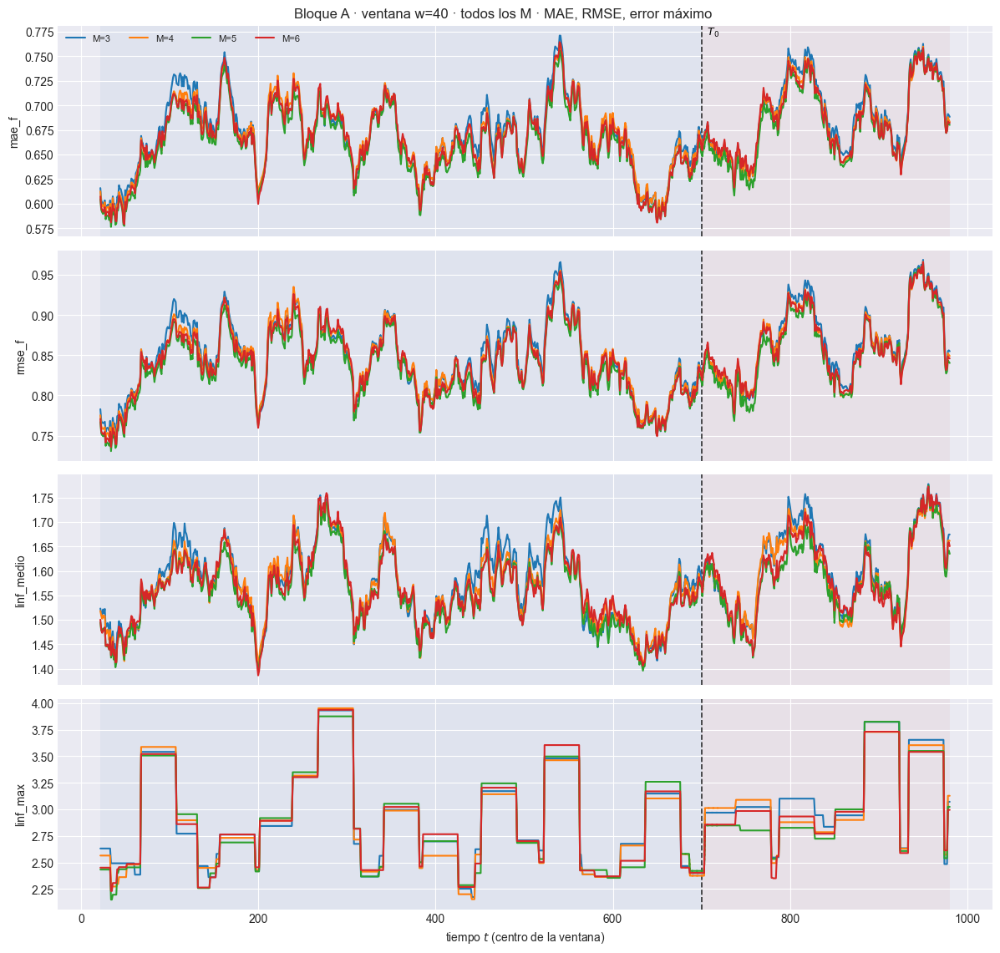

In [7]:
for M in M_OK:
    tablas_ventana(EST[M], DIS, ORIG, PESOS_TAU)
TABLAS_W = apilar_tablas(EST, M_OK, VENTANAS_W, METRICAS_A_COLS + METRICAS_B_COLS)
verificar_relaciones_metricas(EST, M_OK, VENTANAS_W)

# Una figura por ancho con los M superpuestos.
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_A_COLS, columna_grupo="punto",
        title=f"Bloque A · ventana w={w} · todos los M · MAE, RMSE, error máximo",
        save_path=str(PATH_BARRIDO / f"85_bloqueA_w{w}.png"), verbose=(w == W_REF))
    plt.show()

### 4.1 ¿Qué $M$ gana en cada ventana, y en cada ancho?


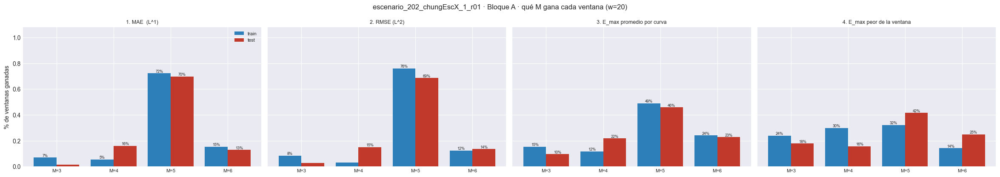

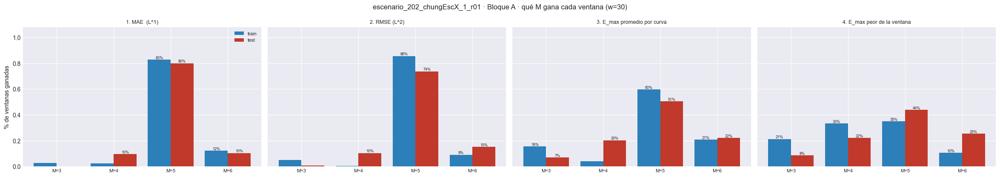

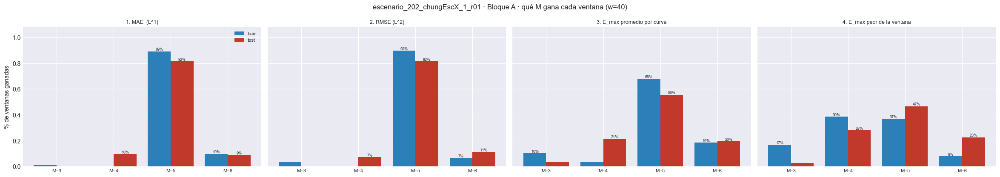

In [8]:
GANA_A = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_A, NIVEL)
GANA_B = ganancias_por_ventana(EST, M_OK, VENTANAS_W, METRICAS_B, NIVEL)
GANA_A.to_csv(PATH_BARRIDO / "84_ganador_por_ventana.csv", index=False)
GANA_B.to_csv(PATH_BARRIDO / "87_ganador_bloqueB.csv", index=False)

for w in VENTANAS_W:
    plot_ganador_ventana(GANA_A, METRICAS_A, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque A · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"84_ganador_por_ventana_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_A).style.format("{:.1%}")
        .set_caption("Bloque A · % de ventanas TEST ganadas por M (84_ganador_por_ventana.csv)"))

# Salto del MISE en T0, sin las ventanas que lo cruzan.
display(saltos_T0(EST, M_OK, VENTANAS_W).set_index(["M", "w"]).style
        .format({"mise_train": "{:.6f}", "mise_test": "{:.6f}", "salto": "{:.2f}x"})
        .set_caption("MISE train / test y salto en T0"))

## 5. Bloque B: intervalos de predicción, en una sola vista

Cuatro cifras del intervalo, ninguna "primaria" en esta vista -el Winkler es
la única regla de puntuación propia y por eso es la que ordena modelos cuando
hace falta ordenar, pero aquí se muestran las cuatro juntas-:

| | qué es | de qué es |
|---|---|---|
| **Winkler** | interval score | penaliza ancho Y cobertura a la vez |
| **Cobertura simultánea** | de $w$ curvas, cuántas quedan COMPLETAS dentro de su banda (1/0 por curva) | fracción de CURVAS |
| **Cobertura puntual (PICP)** | de una curva, qué fracción de $\tau$ cae dentro | promedio de esa fracción sobre la ventana |
| **MPIW** | ancho medio de la banda | — |

La cobertura simultánea es SIEMPRE $\le$ la puntual: basta un $\tau$ fuera
para que la curva entera cuente como no cubierta.

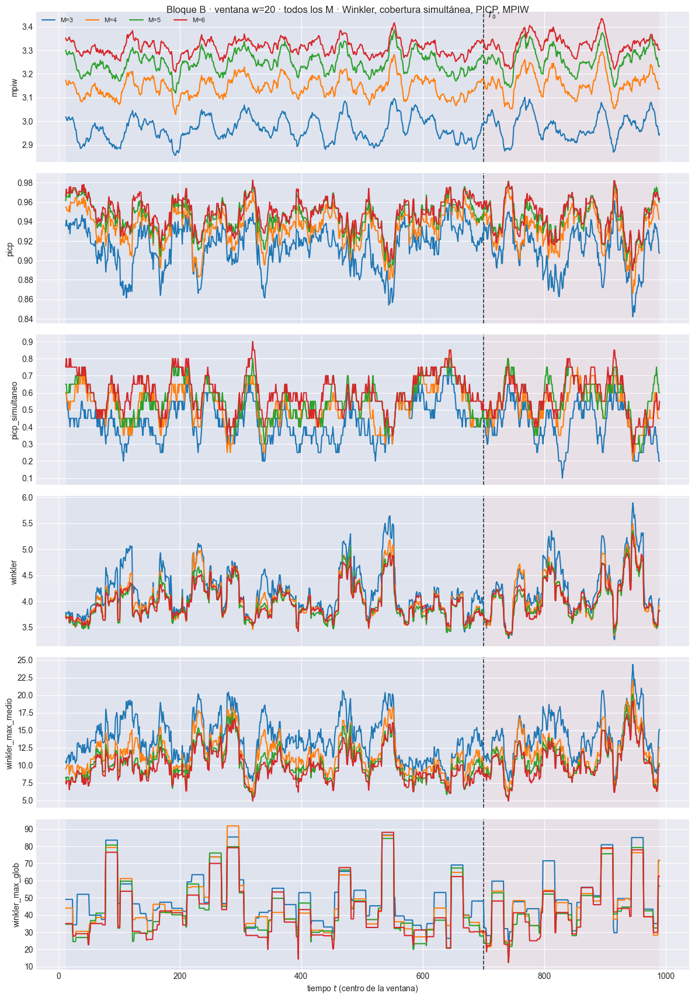

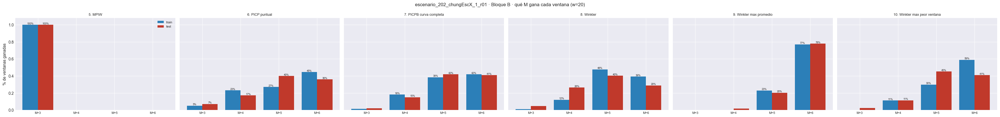

[plot_ventana_movil] inicio (6 pasos)
  1/6 (16.7%) t=0.0s eta=0.1s  mpiw: w=30 train=3.198  w=30 test=3.21
  2/6 (33.3%) t=0.0s eta=0.1s  picp: w=30 train=0.9382  w=30 test=0.9342
  3/6 (50.0%) t=0.0s eta=0.0s  picp_simultaneo: w=30 train=0.5333  w=30 test=0.5333
  4/6 (66.7%) t=0.1s eta=0.0s  winkler: w=30 train=3.955  w=30 test=4.055
  5/6 (83.3%) t=0.1s eta=0.0s  winkler_max_medio: w=30 train=10.8  w=30 test=11.66
  6/6 (100.0%) t=0.1s eta=0.0s  winkler_max_glob: w=30 train=46.93  w=30 test=51.32
[plot_ventana_movil] listo: 6 pasos en 0.6s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_barrido_M\86_bloqueB_w30.png


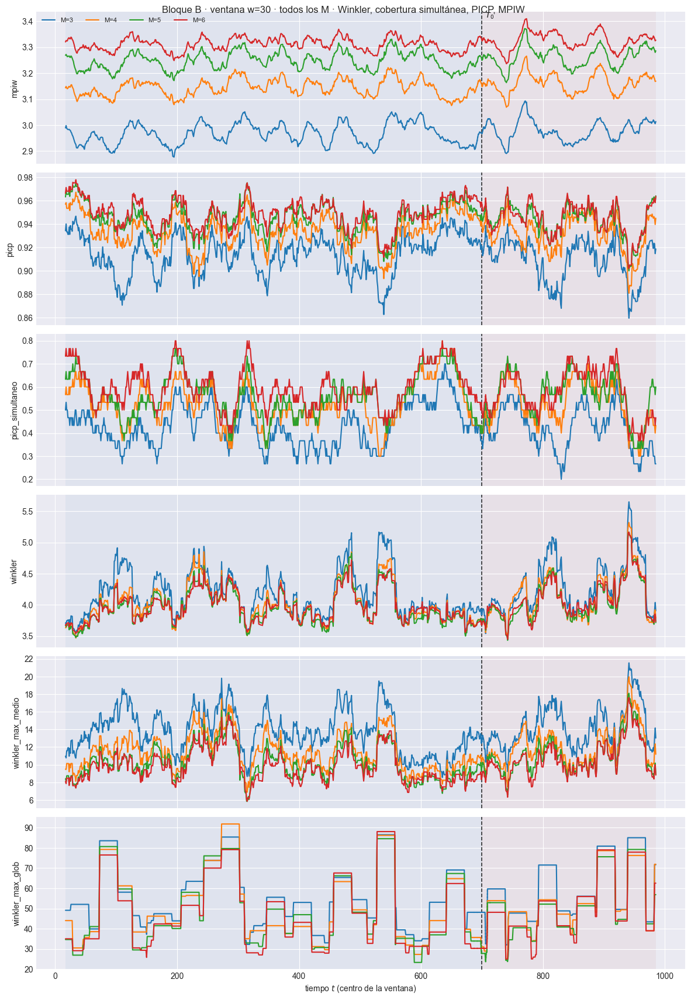

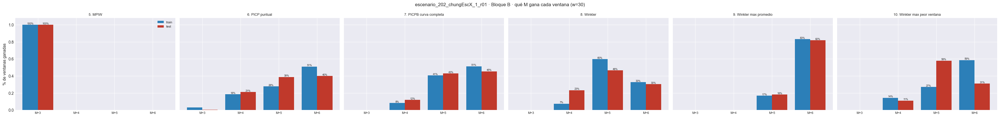

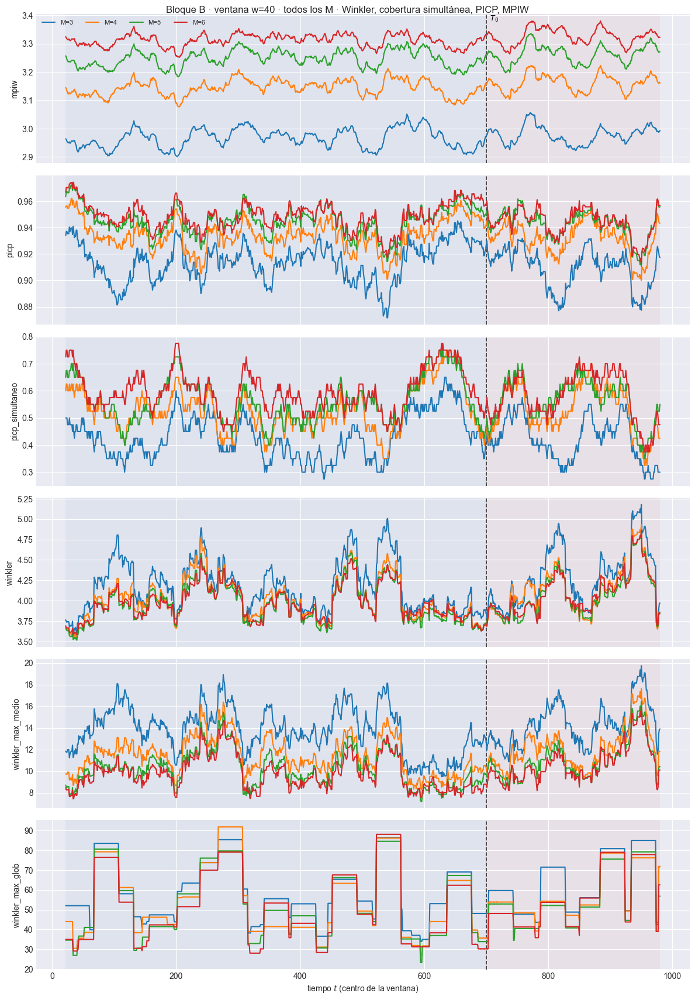

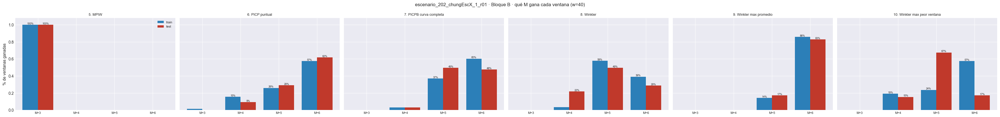

In [9]:
for w in VENTANAS_W:
    plot_ventana_movil(
        TABLAS_W[w], T0, METRICAS_B_COLS, columna_grupo="punto",
        title=f"Bloque B · ventana w={w} · todos los M · Winkler, cobertura simultánea, PICP, MPIW",
        save_path=str(PATH_BARRIDO / f"86_bloqueB_w{w}.png"), verbose=(w == W_REF))
    plt.show()
    # En picp el objetivo es el NOMINAL, no el mínimo.
    plot_ganador_ventana(GANA_B, METRICAS_B, w, M_OK,
                         f"{EXPERIMENT_BASE} · Bloque B · qué M gana cada ventana (w={w})",
                         PATH_BARRIDO / f"87_ganador_bloqueB_w{w}.png")
    plt.show()

display(tabla_ganadores_test(GANA_B).style.format("{:.1%}")
        .set_caption("Bloque B · % de ventanas TEST ganadas por M (87_ganador_bloqueB.csv)"))

## 6. Muestra de predicciones

Dos vistas: un extracto regular del bloque de **prueba** (para no mezclar con
in-sample), y las ventanas con **peor** valor de `METRICA_PEORES` ([CONFIG]).
En la segunda se agrega la curva **anterior** ($t-1$, gris punteada): es el
primer diagnóstico de POR QUÉ el modelo se equivocó -¿la curva de partida ya
era atípica?-.

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=0.933 rmse=0.7473
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=0.640 rmse=1.179
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.733 rmse=1.227
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=0.947 rmse=0.8106
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=0.973 rmse=0.6748
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.7214
  7/10 (70.0%) t=0.0s eta=0.0s  t=881 [test] cob=1.000 rmse=0.6784
  8/10 (80.0%) t=0.0s eta=0.0s  t=911 [test] cob=1.000 rmse=0.7479
  9/10 (90.0%) t=0.1s eta=0.0s  t=941 [test] cob=0.693 rmse=1.377
  10/10 (100.0%) t=0.1s eta=0.0s  t=971 [test] cob=0.987 rmse=0.7268
[plot_extractos_curvas] listo: 10 pasos en 1.0s  cob media train=nan test=0.891 (nominal 0.95)


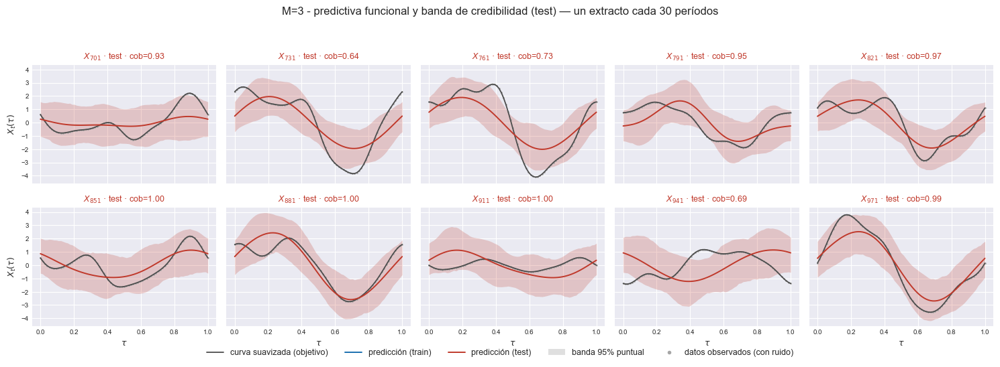

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=0.960 rmse=0.7738
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=0.680 rmse=1.185
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.773 rmse=1.234
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=1.000 rmse=0.8089
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=1.000 rmse=0.6712
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.7737
  7/10 (70.0%) t=0.0s eta=0.0s  t=881 [test] cob=1.000 rmse=0.7145
  8/10 (80.0%) t=0.0s eta=0.0s  t=911 [test] cob=1.000 rmse=0.7579
  9/10 (90.0%) t=0.0s eta=0.0s  t=941 [test] cob=0.693 rmse=1.312
  10/10 (100.0%) t=0.0s eta=0.0s  t=971 [test] cob=0.947 rmse=0.7863
[plot_extractos_curvas] listo: 10 pasos en 0.9s  cob media train=nan test=0.905 (nominal 0.95)


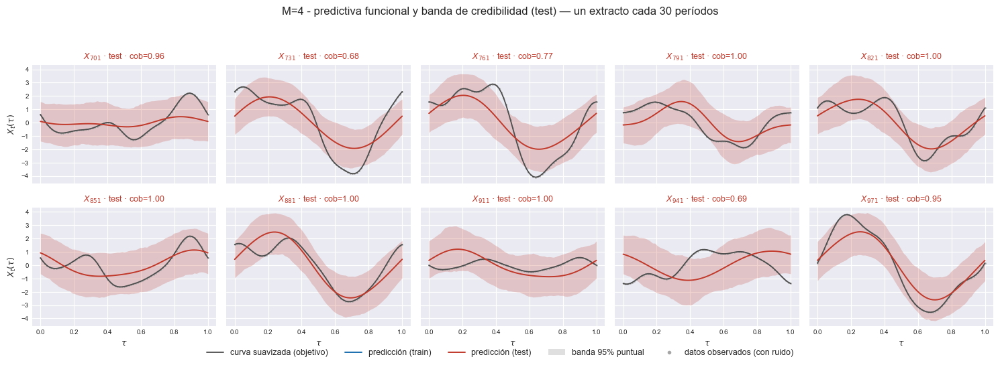

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=0.947 rmse=0.7476
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=0.720 rmse=1.189
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.787 rmse=1.224
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=0.973 rmse=0.8239
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=1.000 rmse=0.6069
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.7492
  7/10 (70.0%) t=0.0s eta=0.0s  t=881 [test] cob=0.987 rmse=0.71
  8/10 (80.0%) t=0.0s eta=0.0s  t=911 [test] cob=1.000 rmse=0.7398
  9/10 (90.0%) t=0.0s eta=0.0s  t=941 [test] cob=0.720 rmse=1.371
  10/10 (100.0%) t=0.0s eta=0.0s  t=971 [test] cob=1.000 rmse=0.7583
[plot_extractos_curvas] listo: 10 pasos en 0.9s  cob media train=nan test=0.913 (nominal 0.95)


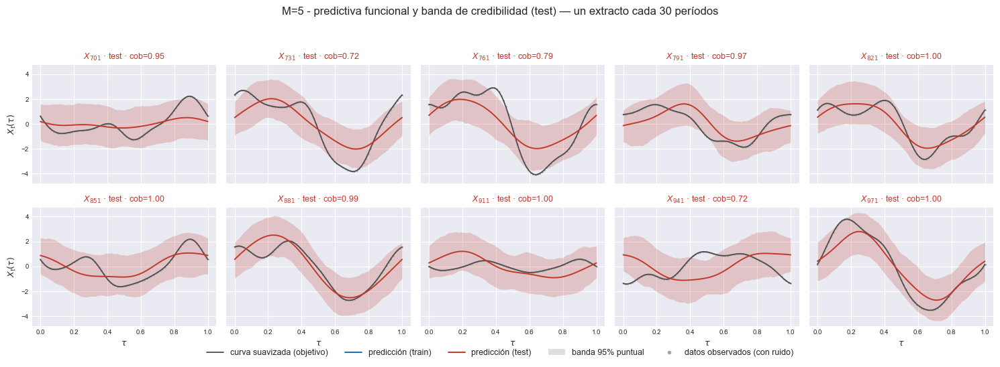

[plot_extractos_curvas] inicio (10 pasos)
  1/10 (10.0%) t=0.0s eta=0.0s  t=701 [test] cob=0.933 rmse=0.7798
  2/10 (20.0%) t=0.0s eta=0.0s  t=731 [test] cob=0.693 rmse=1.204
  3/10 (30.0%) t=0.0s eta=0.0s  t=761 [test] cob=0.787 rmse=1.242
  4/10 (40.0%) t=0.0s eta=0.0s  t=791 [test] cob=1.000 rmse=0.8181
  5/10 (50.0%) t=0.0s eta=0.0s  t=821 [test] cob=1.000 rmse=0.6112
  6/10 (60.0%) t=0.0s eta=0.0s  t=851 [test] cob=1.000 rmse=0.8066
  7/10 (70.0%) t=0.0s eta=0.0s  t=881 [test] cob=1.000 rmse=0.7191
  8/10 (80.0%) t=0.0s eta=0.0s  t=911 [test] cob=1.000 rmse=0.762
  9/10 (90.0%) t=0.0s eta=0.0s  t=941 [test] cob=0.720 rmse=1.301
  10/10 (100.0%) t=0.0s eta=0.0s  t=971 [test] cob=0.947 rmse=0.8299
[plot_extractos_curvas] listo: 10 pasos en 1.0s  cob media train=nan test=0.908 (nominal 0.95)


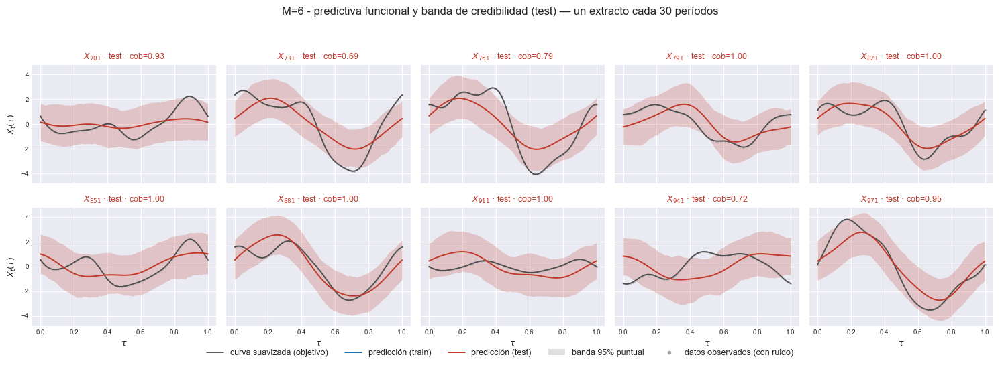

In [10]:
# Extractos regulares, SOLO del bloque de prueba.
mask_test = ~es_train
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[mask_test], e["X_pred"][mask_test], e["li_f"][mask_test], e["ls_f"][mask_test],
        grilla, T0, t=t_orig[mask_test], cada=CADA, n_col=5, nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[mask_test],
        title=f"M={M} - predictiva funcional y banda de credibilidad (test)",
        save_path=str(e["paths"]["out_report"] / "54_extractos_curvas_test.png"), verbose=True)
    plt.show()

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.6338
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.813 rmse=0.9423
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.907 rmse=0.8669
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.6583
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.933 rmse=0.7473
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.7527
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.5407
[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.930 test=0.951 (nominal 0.95)


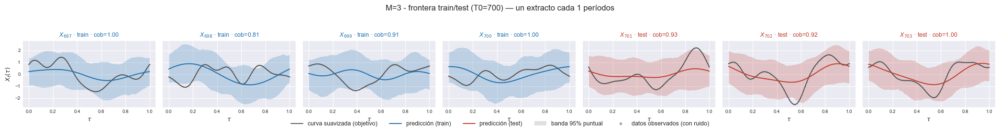

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.6215
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.893 rmse=0.9529
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.947 rmse=0.8822
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.6549
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.960 rmse=0.7738
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.907 rmse=0.7756
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.5195
[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.960 test=0.956 (nominal 0.95)


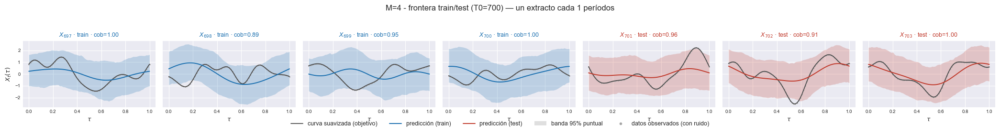

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.6257
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.907 rmse=0.9206
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=0.920 rmse=0.8715
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.661
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.947 rmse=0.7476
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.920 rmse=0.7445
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.4393
[plot_extractos_curvas] listo: 7 pasos en 0.7s  cob media train=0.957 test=0.956 (nominal 0.95)


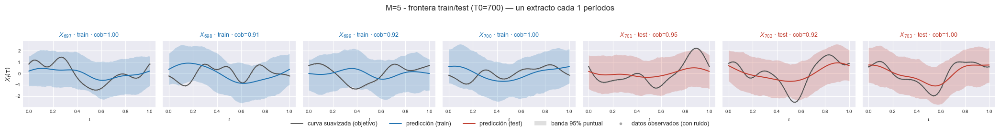

[plot_extractos_curvas] inicio (7 pasos)
  1/7 (14.3%) t=0.0s eta=0.0s  t=697 [train] cob=1.000 rmse=0.6225
  2/7 (28.6%) t=0.0s eta=0.0s  t=698 [train] cob=0.920 rmse=0.9574
  3/7 (42.9%) t=0.0s eta=0.0s  t=699 [train] cob=1.000 rmse=0.8774
  4/7 (57.1%) t=0.0s eta=0.0s  t=700 [train] cob=1.000 rmse=0.6574
  5/7 (71.4%) t=0.0s eta=0.0s  t=701 [test] cob=0.933 rmse=0.7798
  6/7 (85.7%) t=0.0s eta=0.0s  t=702 [test] cob=0.907 rmse=0.7868
  7/7 (100.0%) t=0.0s eta=0.0s  t=703 [test] cob=1.000 rmse=0.4637
[plot_extractos_curvas] listo: 7 pasos en 0.6s  cob media train=0.980 test=0.947 (nominal 0.95)


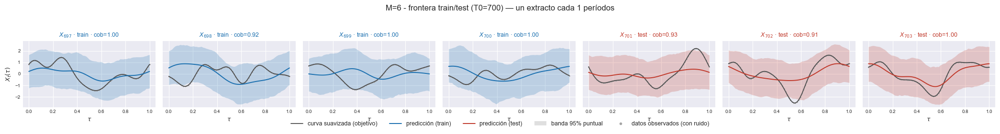

In [11]:
# Zoom sobre la frontera: los últimos orígenes de train y los primeros de test.
i_corte = int(np.searchsorted(t_orig, T0))
sel = np.arange(max(0, i_corte - 3), min(n_orig, i_corte + 4))
for M in M_OK:
    e = EST[M]
    plot_extractos_curvas(
        X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
        t=t_orig[sel], cada=1, n_col=len(sel), nivel=NIVEL,
        etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
        title=f"M={M} - frontera train/test (T0={T0})",
        save_path=str(e["paths"]["out_report"] / "55_extractos_frontera.png"), verbose=True)
    plt.show()

[M=3] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[927, 956]  rmse_f=1.006326


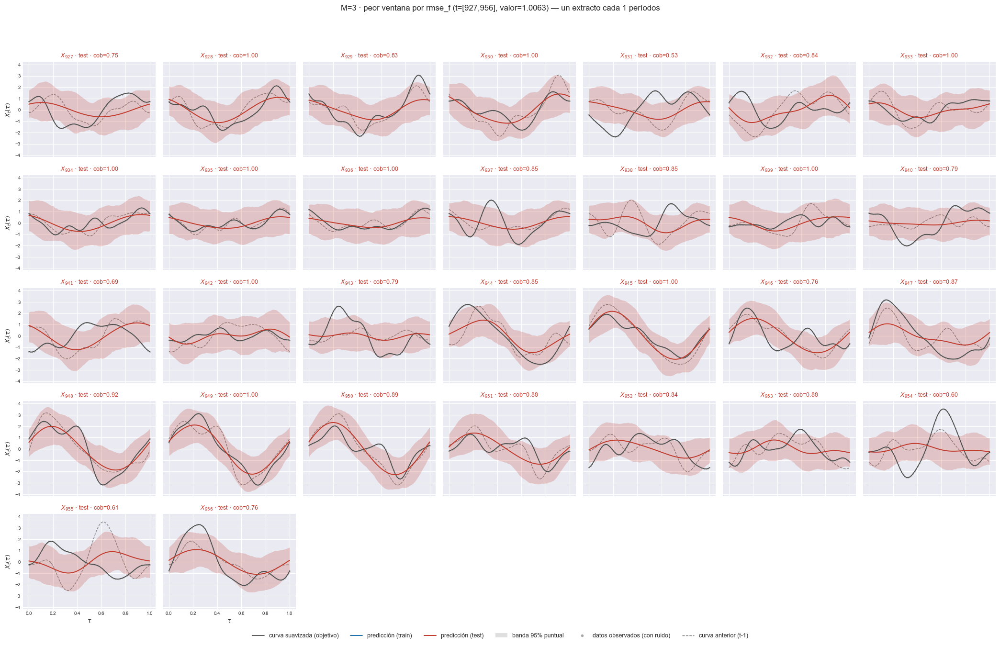

    t=[931, 960]  rmse_f=1.004521


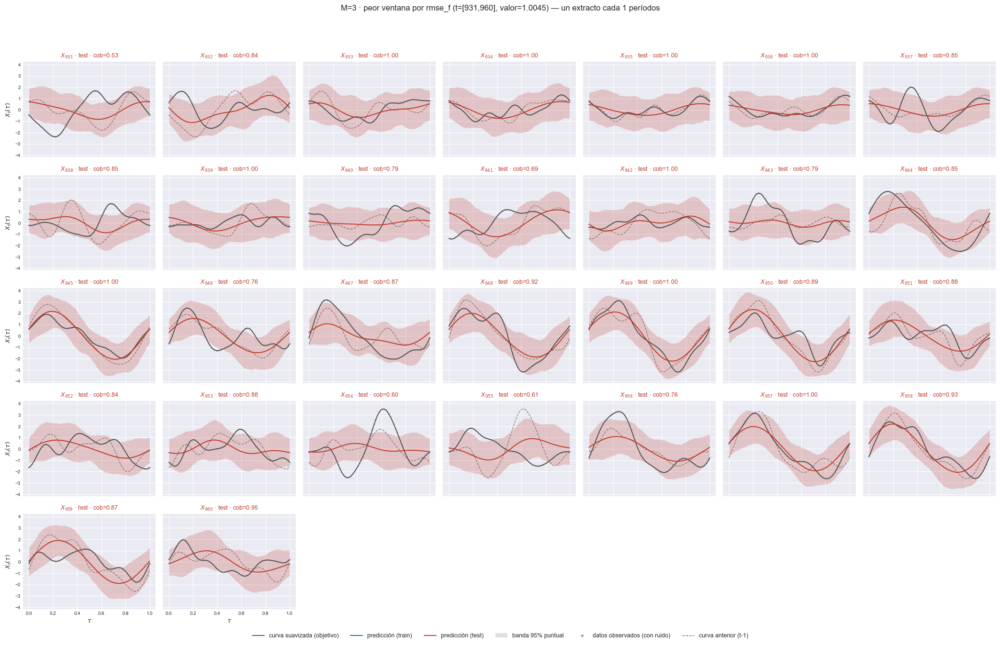

    t=[930, 959]  rmse_f=0.996156


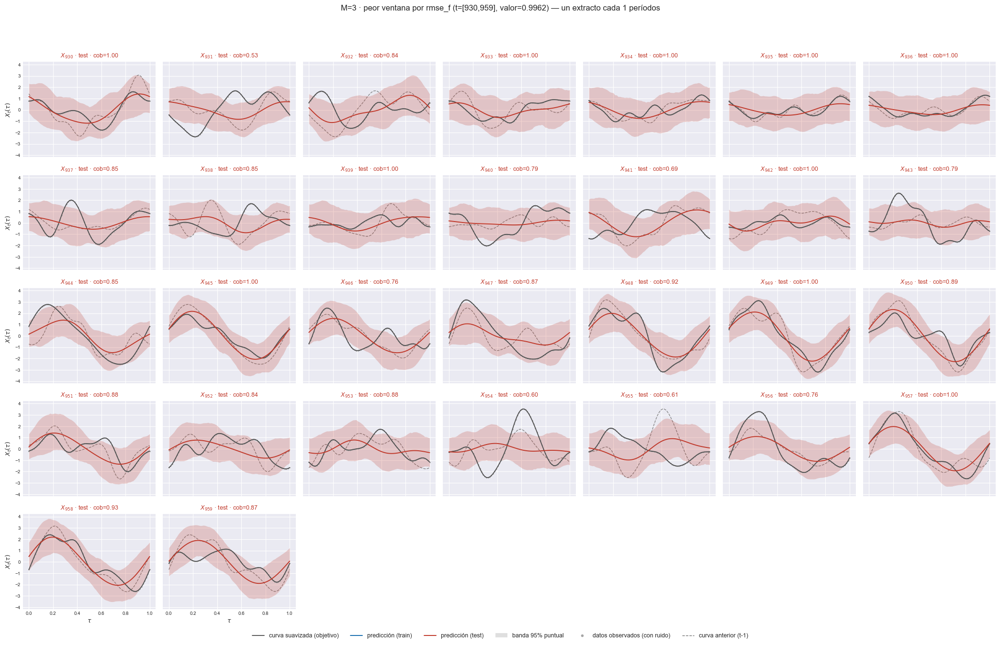

    t=[929, 958]  rmse_f=0.994381


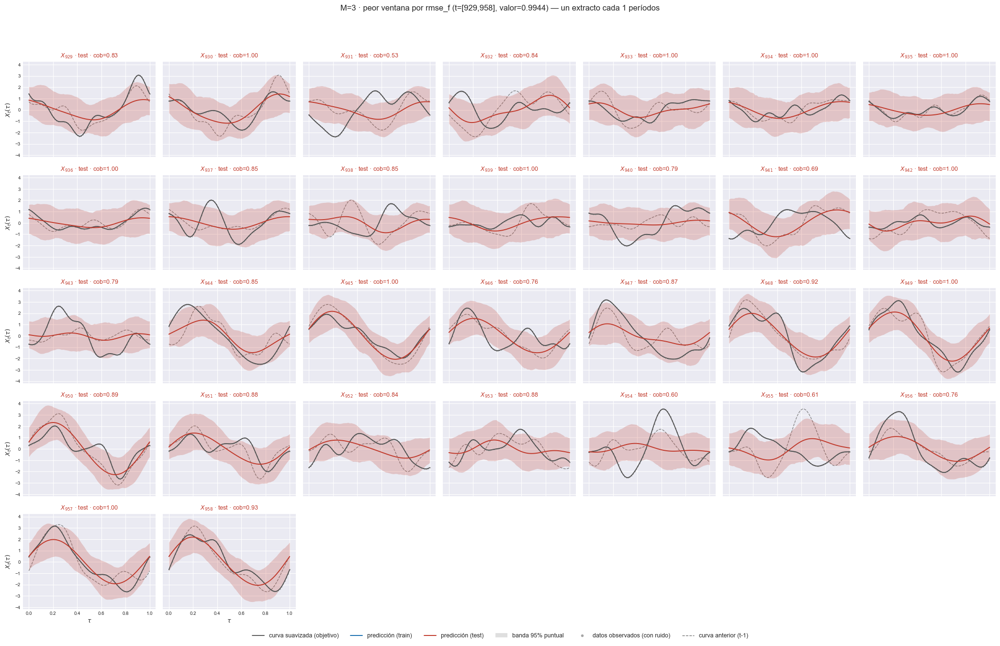

    t=[926, 955]  rmse_f=0.990282


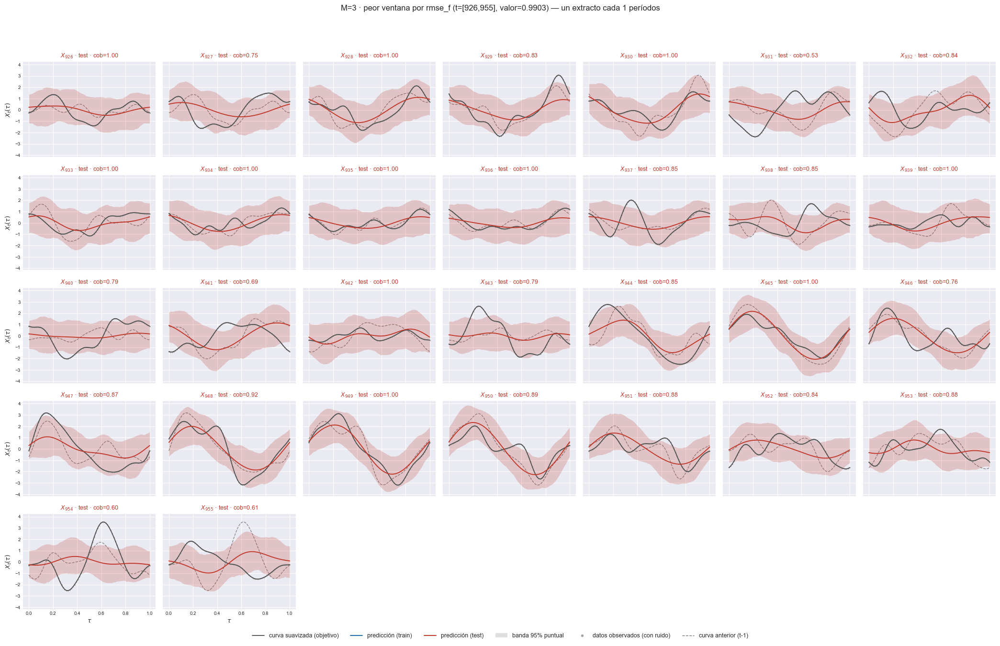

[M=4] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[927, 956]  rmse_f=0.999040


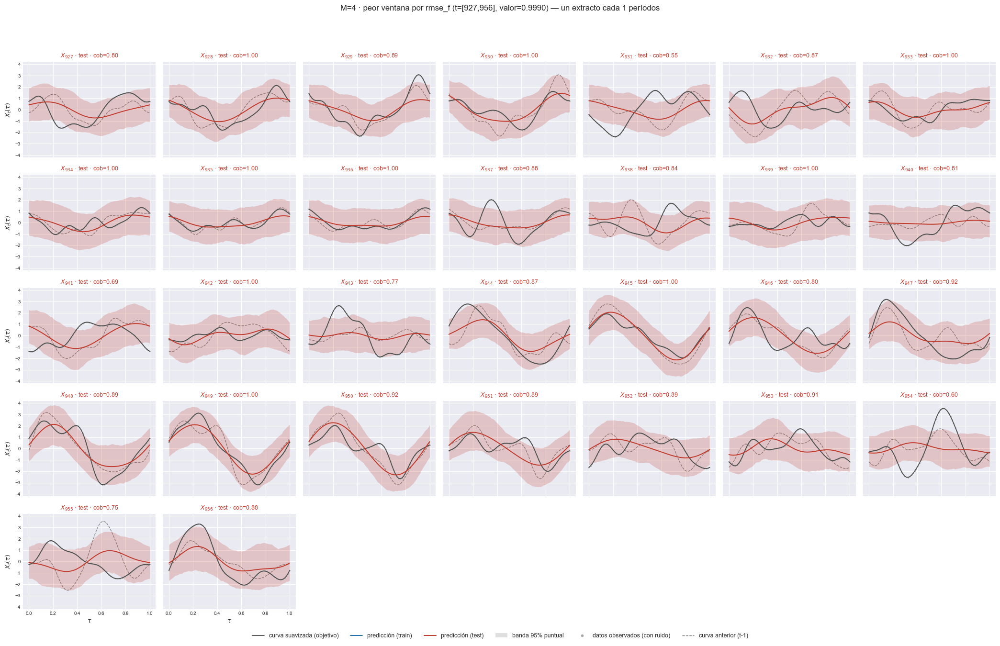

    t=[931, 960]  rmse_f=0.997712


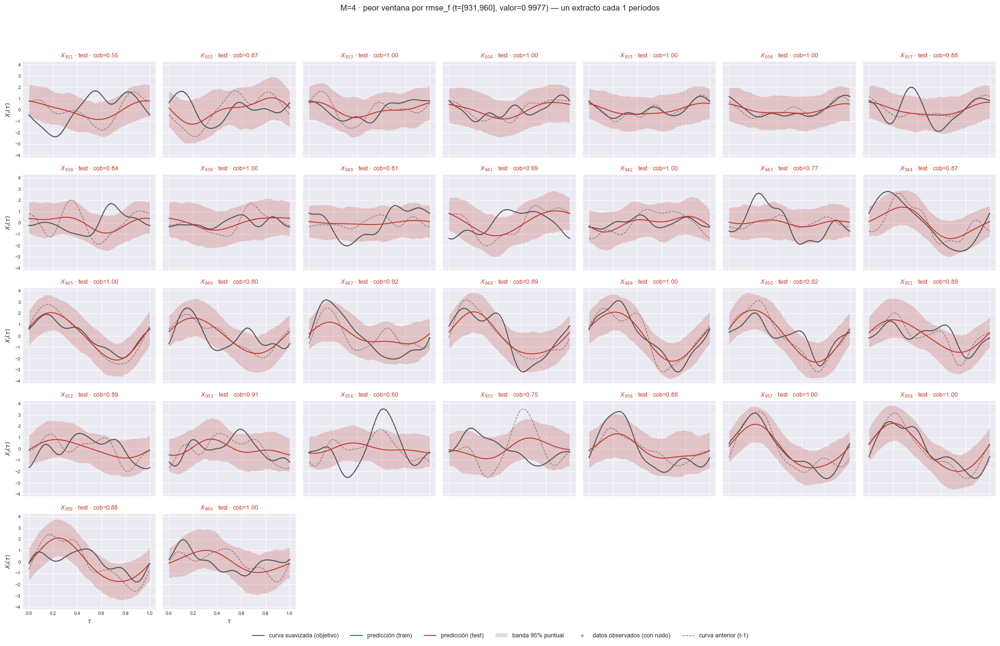

    t=[930, 959]  rmse_f=0.989208


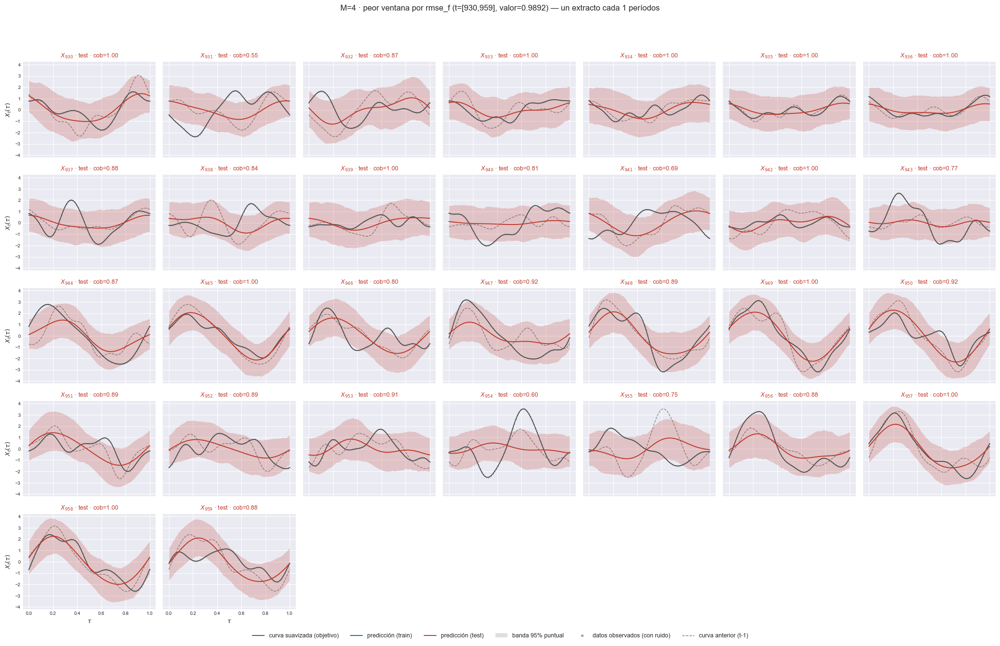

    t=[926, 955]  rmse_f=0.986193


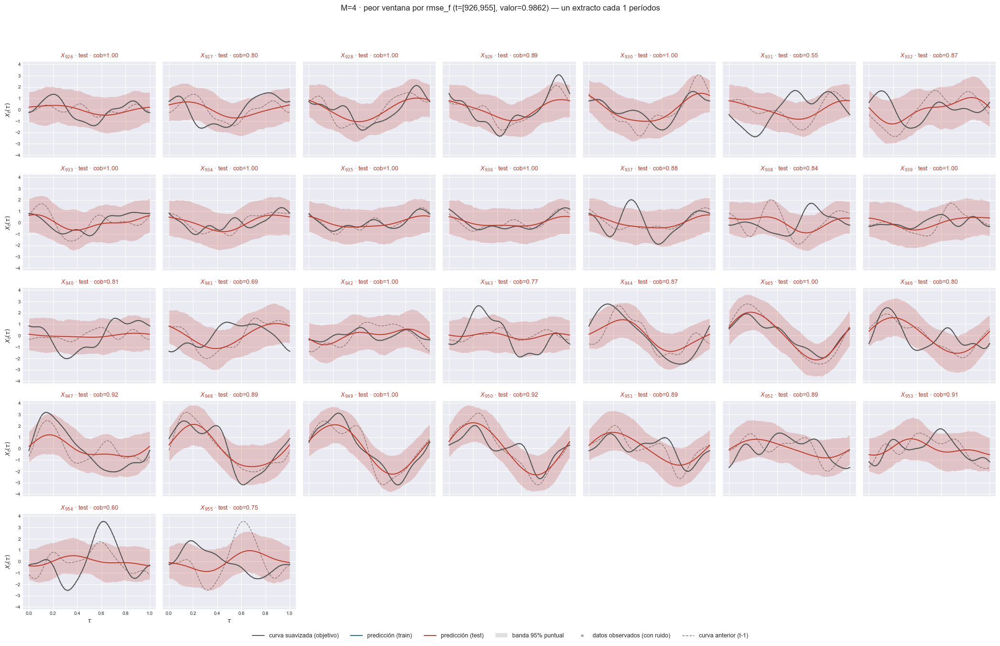

    t=[929, 958]  rmse_f=0.986067


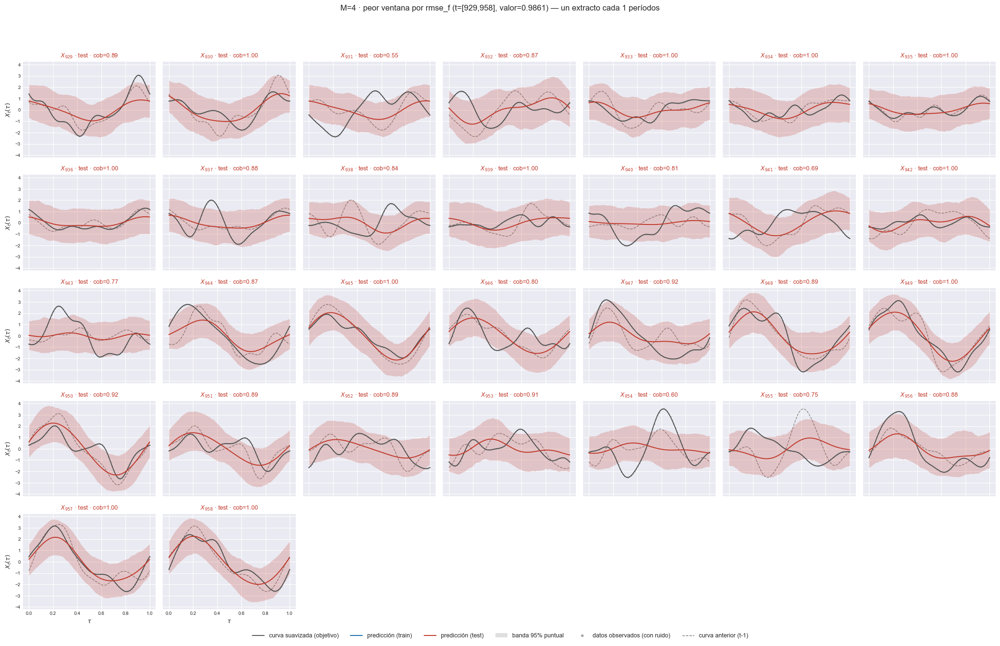

[M=5] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[927, 956]  rmse_f=1.002323


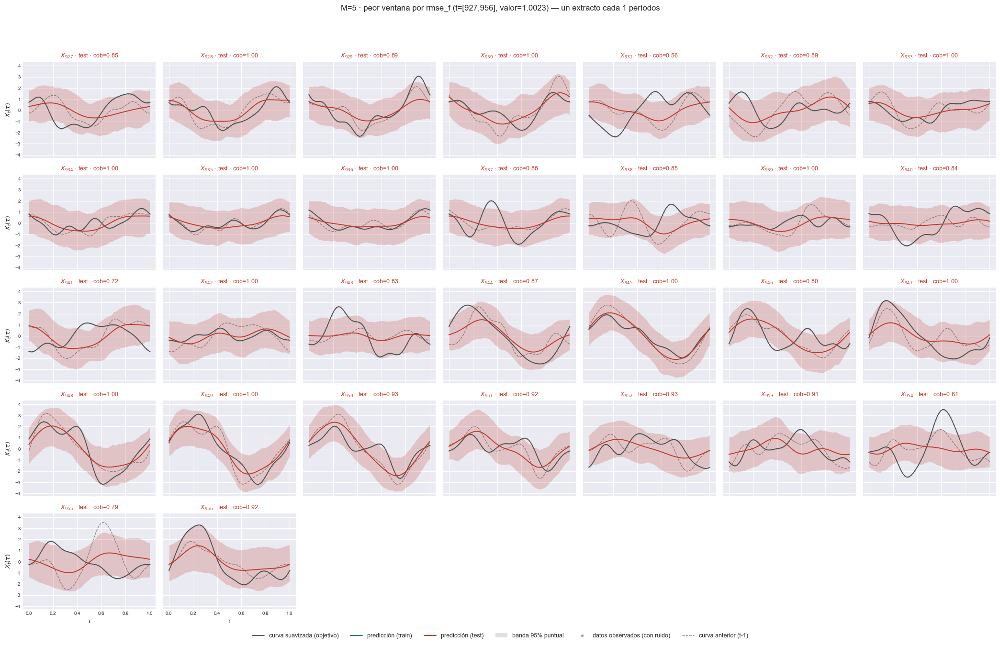

    t=[931, 960]  rmse_f=0.999790


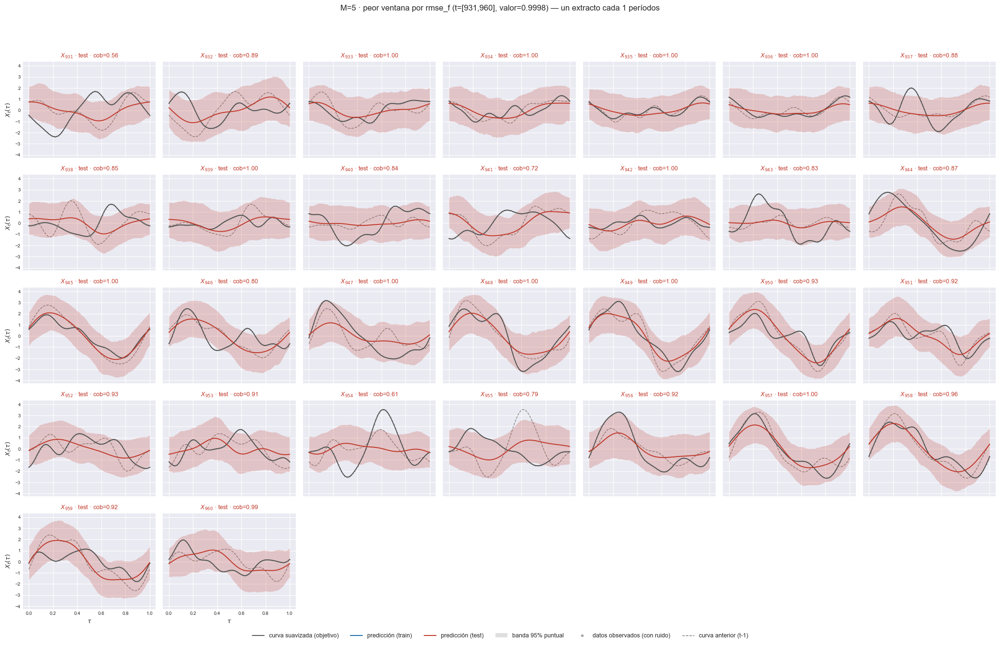

    t=[930, 959]  rmse_f=0.992291


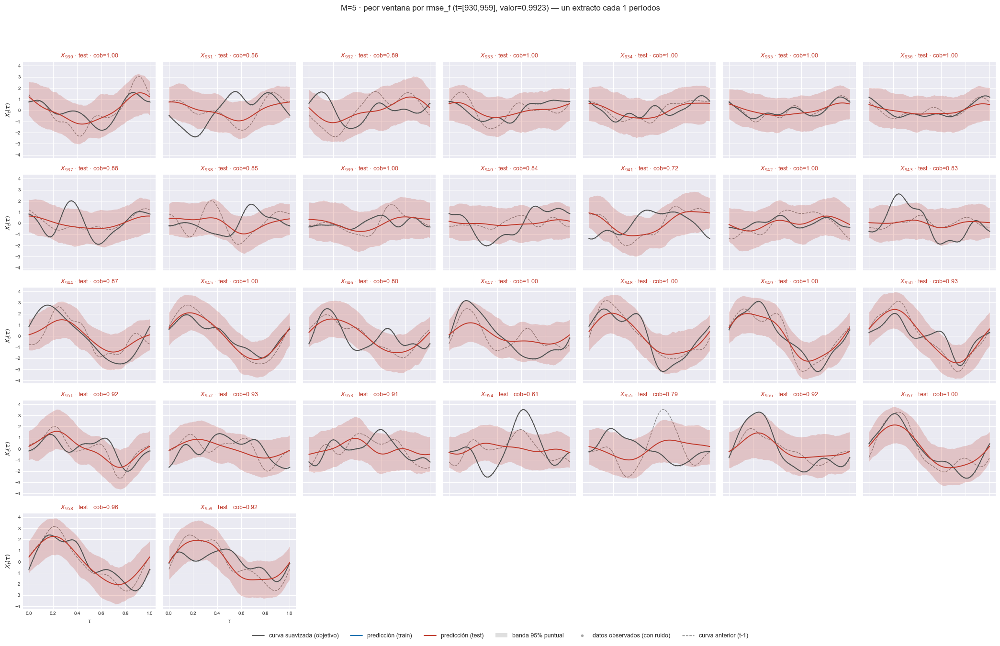

    t=[926, 955]  rmse_f=0.990400


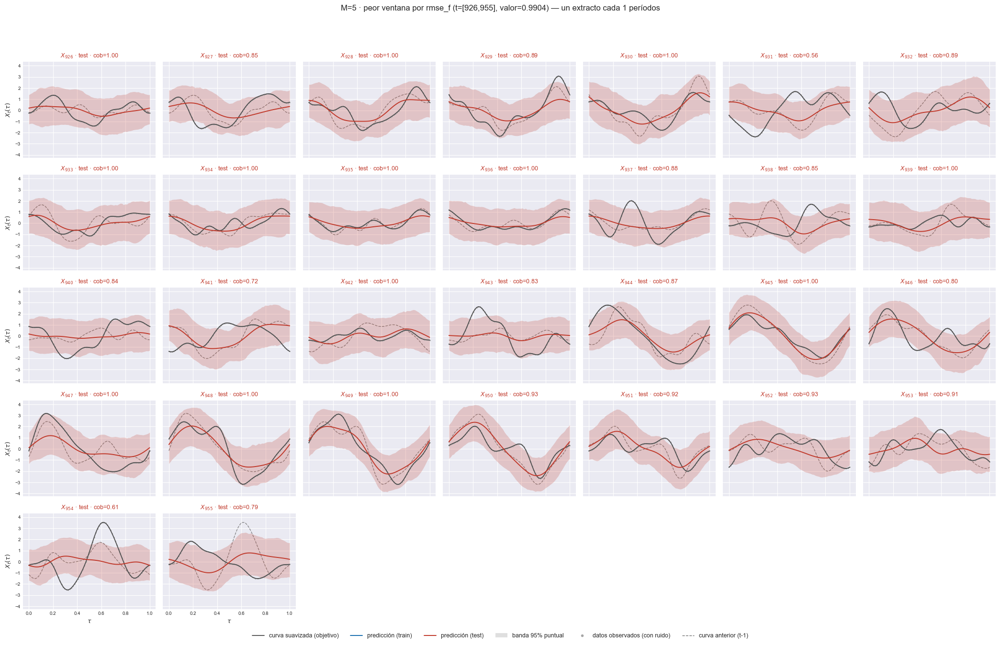

    t=[929, 958]  rmse_f=0.989164


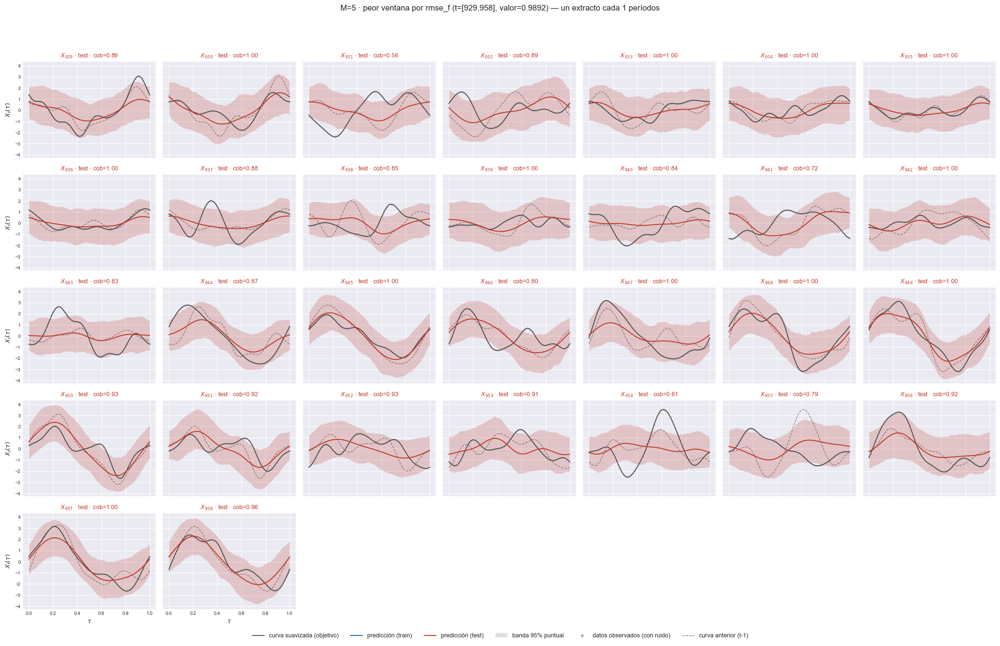

[M=6] peores 5 ventanas por rmse_f (w=30, test, sin cruzar T0)
    t=[927, 956]  rmse_f=1.001786


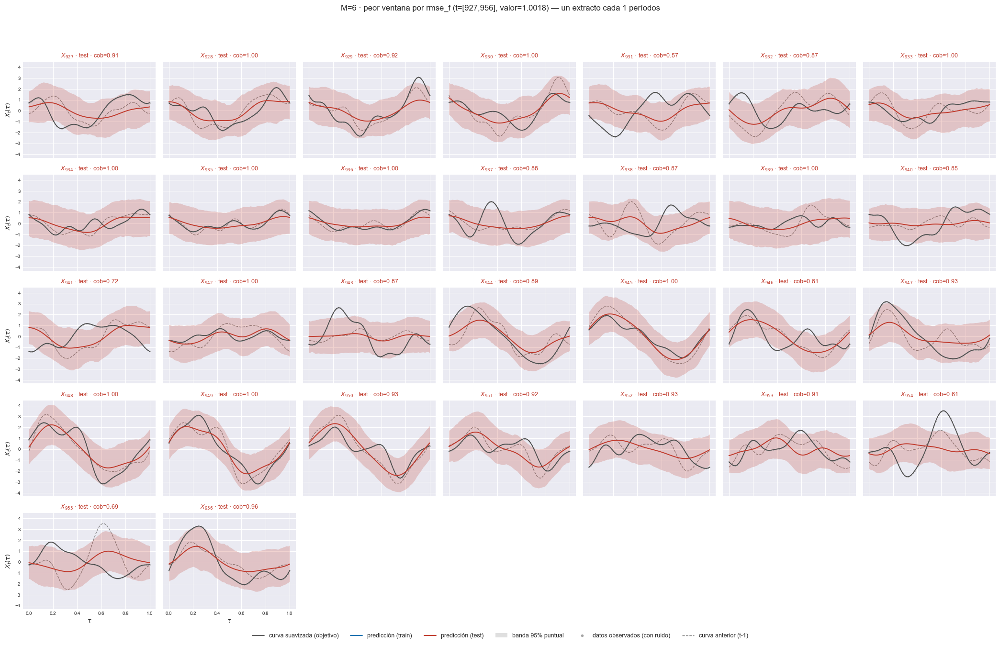

    t=[931, 960]  rmse_f=0.996825


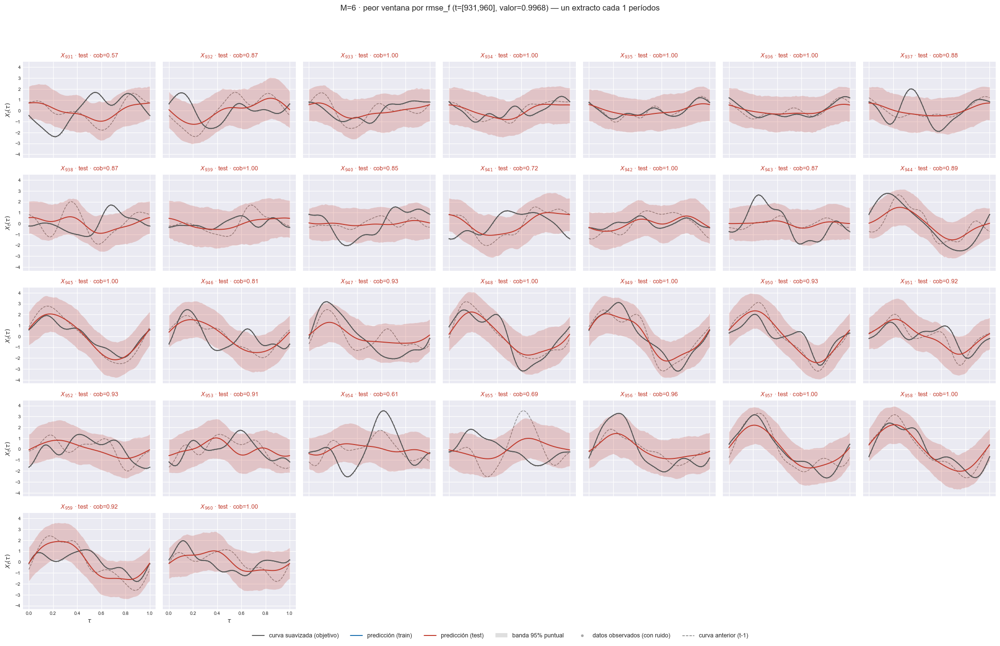

    t=[926, 955]  rmse_f=0.990130


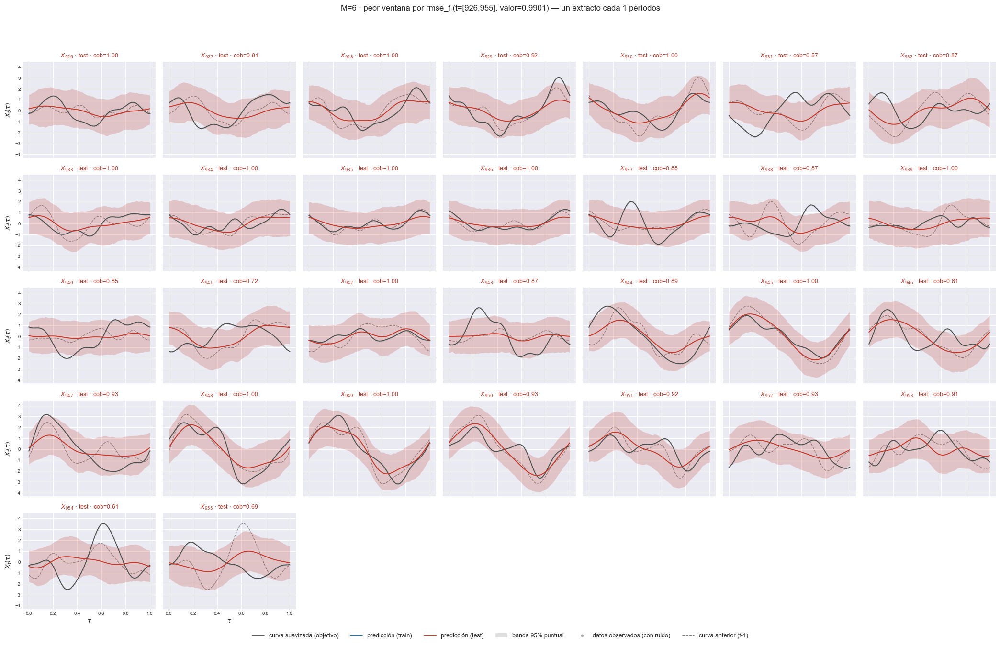

    t=[930, 959]  rmse_f=0.989669


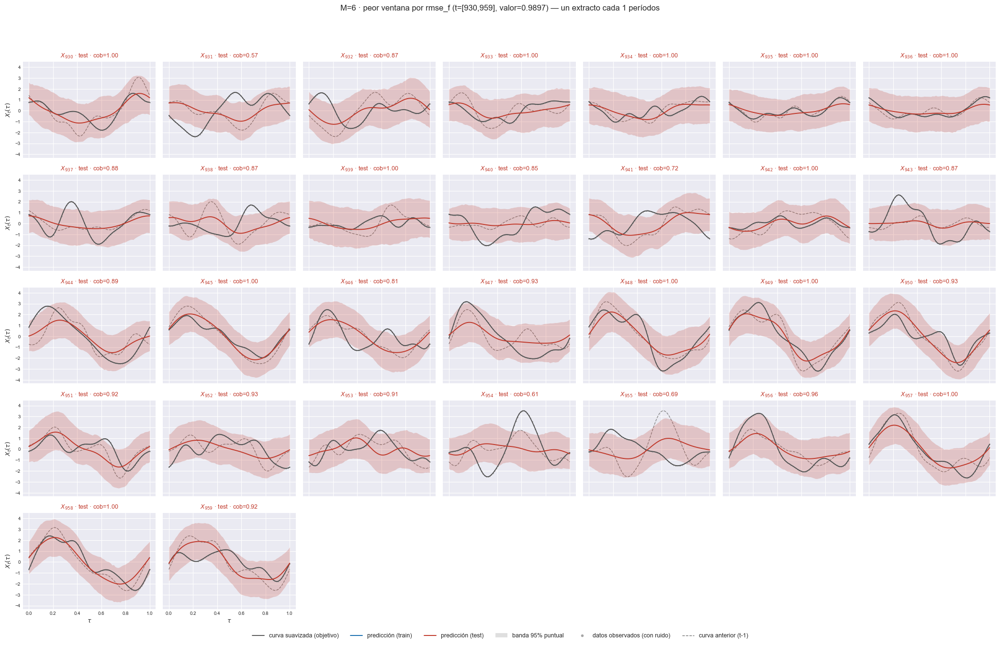

    t=[929, 958]  rmse_f=0.987287


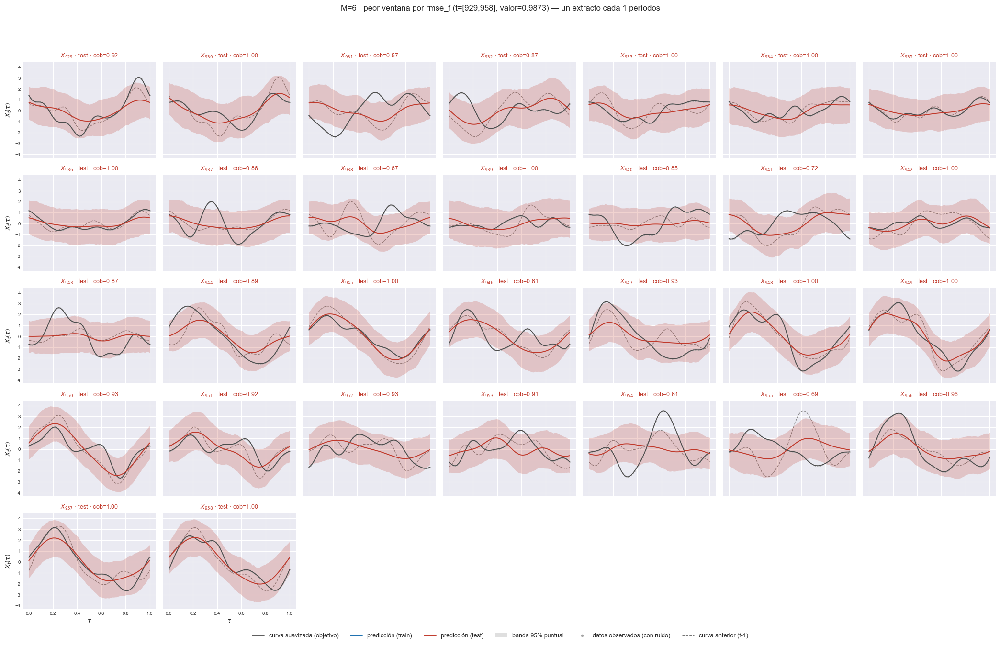

In [12]:
# Peores ventanas de test, con la curva anterior (t-1) al lado.
X_prev_full = np.full_like(X_obj_ev, np.nan)
X_prev_full[1:] = X_obj_ev[:-1]

for M in M_OK:
    e = EST[M]
    peores = peores_ventanas(e, W_REF, METRICA_PEORES, N_PEORES)
    print(f"[M={M}] peores {len(peores)} ventanas por {METRICA_PEORES} (w={W_REF}, test, sin cruzar T0)")
    for _, row in peores.iterrows():
        ini, fin = int(row["t_ini"]), int(row["t_fin"])
        print(f"    t=[{ini}, {fin}]  {METRICA_PEORES}={row[METRICA_PEORES]:.6f}")
        sel = np.where((t_orig >= ini) & (t_orig <= fin))[0]
        if sel.size == 0:
            continue
        plot_extractos_curvas(
            X_obj_ev[sel], e["X_pred"][sel], e["li_f"][sel], e["ls_f"][sel], grilla, T0,
            t=t_orig[sel], cada=1, n_col=min(len(sel), 7), nivel=NIVEL,
            etiqueta_objetivo="curva suavizada (objetivo)", X_obs=X_obs_ev[sel],
            X_prev=X_prev_full[sel],
            title=f"M={M} · peor ventana por {METRICA_PEORES} (t=[{ini},{fin}], "
                  f"valor={row[METRICA_PEORES]:.4f})",
            save_path=str(e["paths"]["out_report"] / f"56b_peor_ventana_{METRICA_PEORES}_t{ini}.png"),
            verbose=False)
        plt.show()

## 7. Probabilidades posteriores de inclusión (PIP)

El soporte verdadero sale de `internos["soporte"]` del generador: qué pares (score, rezago) entran en $E[\xi_{j,t}\mid\text{pasado}]$ —los no nulos de $A_{k,l}$ o de $f_k$ y, donde los mecanismos difieren, las covariables de $q_k$—. Es disperso, así que sensibilidad, especificidad y AUC sí son informativas. Con $M<4$ parte del soporte no existe como covariable. El PIP se calcula sobre los scores **estimados**: el contraste es directo sólo si $\psi_k\approx\varphi_k$ (`_03` §6.1 imprime $|\cos(\psi_k,\varphi_k)|$).


In [13]:
for M in M_OK:
    pip_df = pip_punto(EST[M], SD_PIP_MAX)
    display(pip_df.style
        .background_gradient(subset=[c for c in pip_df.columns if not c.endswith("_sd")],
                             cmap="RdYlGn", vmin=0, vmax=1)
        .format("{:.3f}")
        .set_caption(f"M={M} · P(gamma_j = 1 | datos), inclusión global, media entre cadenas ± sd"))

[matriz_pip] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 6 variables, PIP en [0.037, 1.000]
  2/3 (66.7%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 6 variables, PIP en [0.050, 1.000]
  3/3 (100.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 6 variables, PIP en [0.063, 1.000]
[matriz_pip] listo: 3 pasos en 0.0s  tabla 6x6
[M=3] dispersion maxima entre cadenas: 0.560   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd
variable,,,,,,
fpc_1_lag1,1.000,0.000,0.677,0.560,0.065,0.019
fpc_2_lag1,0.050,0.011,1.000,0.000,1.000,0.000
fpc_3_lag1,0.054,0.022,0.066,0.023,1.000,0.000
fpc_1_lag2,0.573,0.313,0.056,0.019,0.072,0.039
fpc_2_lag2,0.037,0.015,0.050,0.012,0.063,0.018
fpc_3_lag2,0.042,0.011,0.053,0.020,0.081,0.018


[matriz_pip] inicio (4 pasos)
  1/4 (25.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 8 variables, PIP en [0.025, 1.000]
  2/4 (50.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 8 variables, PIP en [0.037, 1.000]
  3/4 (75.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 8 variables, PIP en [0.054, 1.000]
  4/4 (100.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 8 variables, PIP en [0.089, 1.000]
[matriz_pip] listo: 4 pasos en 0.0s  tabla 8x8
[M=4] dispersion maxima entre cadenas: 0.557   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd
variable,,,,,,,,
fpc_1_lag1,1.000,0.000,0.357,0.557,0.057,0.011,0.168,0.132
fpc_2_lag1,0.027,0.001,1.000,0.000,1.000,0.000,0.097,0.005
fpc_3_lag1,0.049,0.038,0.063,0.031,1.000,0.000,0.094,0.027
fpc_4_lag1,0.033,0.009,0.037,0.009,0.054,0.017,1.000,0.000
fpc_1_lag2,0.961,0.036,0.041,0.011,0.064,0.015,0.091,0.017
fpc_2_lag2,0.025,0.006,0.041,0.019,0.057,0.004,0.099,0.012
fpc_3_lag2,0.029,0.017,0.040,0.007,0.080,0.030,1.000,0.000
fpc_4_lag2,0.030,0.013,0.037,0.007,0.063,0.006,0.089,0.002


[matriz_pip] inicio (5 pasos)
  1/5 (20.0%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 10 variables, PIP en [0.040, 1.000]
  2/5 (40.0%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 10 variables, PIP en [0.024, 1.000]
  3/5 (60.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 10 variables, PIP en [0.045, 1.000]
  4/5 (80.0%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 10 variables, PIP en [0.054, 1.000]
  5/5 (100.0%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 10 variables, PIP en [0.049, 1.000]
[matriz_pip] listo: 5 pasos en 0.0s  tabla 10x10
[M=5] dispersion maxima entre cadenas: 0.560   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd
variable,,,,,,,,,,
fpc_1_lag1,1.000,0.000,0.677,0.560,0.052,0.019,0.690,0.538,0.102,0.053
fpc_2_lag1,0.053,0.022,1.000,0.000,1.000,0.000,0.070,0.018,0.059,0.014
fpc_3_lag1,0.046,0.011,0.277,0.404,1.000,0.000,0.077,0.005,0.050,0.010
fpc_4_lag1,0.059,0.048,0.029,0.005,0.049,0.017,1.000,0.000,0.049,0.016
fpc_5_lag1,0.046,0.025,0.037,0.005,0.045,0.003,0.054,0.020,1.000,0.000
fpc_1_lag2,0.873,0.137,0.027,0.006,0.046,0.010,0.091,0.033,0.077,0.009
fpc_2_lag2,0.044,0.011,0.033,0.005,0.054,0.022,0.081,0.011,0.067,0.029
fpc_3_lag2,0.041,0.010,0.024,0.006,0.069,0.004,1.000,0.000,0.063,0.020
fpc_4_lag2,0.051,0.021,0.032,0.007,0.059,0.018,0.075,0.017,0.050,0.012


[matriz_pip] inicio (6 pasos)
  1/6 (16.7%) t=0.0s eta=0.0s  FPC 1: 3 cadenas, 12 variables, PIP en [0.031, 1.000]
  2/6 (33.3%) t=0.0s eta=0.0s  FPC 2: 3 cadenas, 12 variables, PIP en [0.038, 1.000]
  3/6 (50.0%) t=0.0s eta=0.0s  FPC 3: 3 cadenas, 12 variables, PIP en [0.060, 1.000]
  4/6 (66.7%) t=0.0s eta=0.0s  FPC 4: 3 cadenas, 12 variables, PIP en [0.084, 1.000]
  5/6 (83.3%) t=0.0s eta=0.0s  FPC 5: 3 cadenas, 12 variables, PIP en [0.054, 1.000]
  6/6 (100.0%) t=0.0s eta=0.0s  FPC 6: 3 cadenas, 12 variables, PIP en [0.052, 1.000]
[matriz_pip] listo: 6 pasos en 0.0s  tabla 12x12
[M=6] dispersion maxima entre cadenas: 0.552   ! las cadenas discrepan sobre la seleccion


,FPC 1,FPC 1_sd,FPC 2,FPC 2_sd,FPC 3,FPC 3_sd,FPC 4,FPC 4_sd,FPC 5,FPC 5_sd,FPC 6,FPC 6_sd
variable,,,,,,,,,,,,
fpc_1_lag1,1.000,0.000,0.363,0.552,0.071,0.008,0.105,0.024,0.064,0.028,0.064,0.028
fpc_2_lag1,0.043,0.021,1.000,0.000,1.000,0.000,0.096,0.026,0.062,0.020,0.070,0.012
fpc_3_lag1,0.036,0.006,0.040,0.018,1.000,0.000,0.103,0.015,0.060,0.013,0.067,0.020
fpc_4_lag1,0.035,0.017,0.043,0.028,0.066,0.017,1.000,0.000,0.064,0.019,0.059,0.006
fpc_5_lag1,0.037,0.002,0.040,0.014,0.060,0.009,0.095,0.012,1.000,0.000,0.066,0.022
fpc_6_lag1,0.033,0.006,0.043,0.017,0.066,0.025,0.103,0.041,0.062,0.018,1.000,0.000
fpc_1_lag2,0.664,0.344,0.060,0.027,0.075,0.013,0.109,0.020,0.083,0.024,0.058,0.016
fpc_2_lag2,0.033,0.003,0.050,0.015,0.074,0.013,0.107,0.024,0.069,0.011,0.064,0.022
fpc_3_lag2,0.049,0.008,0.047,0.017,0.346,0.466,1.000,0.000,0.054,0.001,0.052,0.006


In [14]:
for M in M_OK:
    contraste = contraste_generador(EST[M], ESCENARIO_ID, UMBRAL_PIP, COS_MIN)
    if not contraste.empty:
        display(contraste.style.format("{:.3f}", subset=[
            c for c in contraste.columns if contraste[c].dtype.kind == "f"])
            .set_caption(f"M={M} - selección de variables vs soporte del generador "
                         f"(umbral {UMBRAL_PIP})"))

[M=3] |cos(psi_k, phi_k)| = [1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,3,2,0,1,3,0.667,1.000,0.833,0.889,0.541,0.044
FPC 2,3,2,0,1,3,0.667,1.000,0.833,0.889,0.577,0.056
FPC 3,4,2,0,2,2,0.500,1.000,0.667,0.750,0.534,0.072


[M=4] |cos(psi_k, phi_k)| = [1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,3,2,0,1,5,0.667,1.000,0.875,0.733,0.663,0.033
FPC 2,3,1,0,2,5,0.333,1.000,0.750,0.900,0.466,0.044
FPC 3,4,2,0,2,4,0.500,1.000,0.750,0.812,0.530,0.063
FPC 4,5,2,0,3,3,0.400,1.000,0.625,0.800,0.471,0.094


[M=5] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,3,2,0,1,7,0.667,1.000,0.900,0.952,0.642,0.047
FPC 2,3,2,0,1,7,0.667,1.000,0.900,0.714,0.568,0.067
FPC 3,4,2,0,2,6,0.500,1.000,0.800,0.667,0.525,0.055
FPC 4,5,3,0,2,5,0.600,1.000,0.800,0.840,0.570,0.072
FPC 5,1,1,0,0,9,1.000,1.000,1.000,1.000,1.000,0.064


[M=6] |cos(psi_k, phi_k)| = [1. 1. 1. 1. 1. 1.]


,n_activas,VP,FP,FN,VN,sensibilidad,especificidad,exactitud,auc,pip_media_activas,pip_media_inactivas
componente,,,,,,,,,,,
FPC 1,3,2,0,1,9,0.667,1.000,0.917,0.963,0.569,0.037
FPC 2,3,1,0,2,9,0.333,1.000,0.833,1.000,0.474,0.044
FPC 3,4,2,0,2,8,0.500,1.000,0.833,0.781,0.537,0.105
FPC 4,5,2,0,3,7,0.400,1.000,0.750,0.829,0.462,0.098
FPC 5,1,1,0,0,11,1.000,1.000,1.000,1.000,1.000,0.064
FPC 6,1,1,0,0,11,1.000,1.000,1.000,1.000,1.000,0.063


## 8. Cuadro resumen: mínimo, máximo y promedio

La ventana móvil genera una SERIE por métrica, no una cifra. Esta tabla es la
lectura resumida de esa serie: mínimo, máximo y promedio, por bloque
train/test, excluyendo las ventanas que cruzan $T_0$ -su cifra mezcla dentro y
fuera de muestra-. Cubre las 7 métricas de los Bloques A y B; ninguna se
destaca sobre las demás.

In [15]:
# Los dos objetivos en la misma tabla, con la columna que declara cuál.
for M in M_OK:
    resumen = resumen_metricas(EST[M], M, DIS, ORIG)
    display(resumen.style.format({"minimo": "{:.6f}", "maximo": "{:.6f}", "promedio": "{:.6f}"})
            .set_caption(f"M={M} · mínimo / máximo / promedio por ventana "
                         f"(w={W_REF}, sin cruzar T0) · nivel funcional"))

resumen_bar = resumen_barrido(EST, M_OK, PATH_BARRIDO)
# Vista rápida: un solo objetivo (el primario del Bloque A); el CSV tiene los dos.
display(resumen_bar[(resumen_bar.bloque == "test") & (resumen_bar.objetivo == "curva_suavizada")]
        .pivot(index="metrica", columns="M", values="promedio").style.format("{:.6f}")
        .set_caption("Promedio en TEST contra M, objetivo=curva_suavizada (89_resumen_por_M.csv)"))

[M=3] curva_suavizada      PICP puntual test = 0.9082 (nominal 0.95)  ·  PICP simultaneo test = 0.4197
[M=3] representacion_fpca  PICP puntual test = 0.9508 (nominal 0.95)  ·  PICP simultaneo test = 0.7804


[M=4] curva_suavizada      PICP puntual test = 0.9311 (nominal 0.95)  ·  PICP simultaneo test = 0.5315
[M=4] representacion_fpca  PICP puntual test = 0.9481 (nominal 0.95)  ·  PICP simultaneo test = 0.6781


[M=5] curva_suavizada      PICP puntual test = 0.9426 (nominal 0.95)  ·  PICP simultaneo test = 0.5689
[M=5] representacion_fpca  PICP puntual test = 0.9456 (nominal 0.95)  ·  PICP simultaneo test = 0.6549


[M=6] curva_suavizada      PICP puntual test = 0.9439 (nominal 0.95)  ·  PICP simultaneo test = 0.5803
[M=6] representacion_fpca  PICP puntual test = 0.9467 (nominal 0.95)  ·  PICP simultaneo test = 0.6370


M,3,4,5,6
metrica,,,,
1. MAE (L^1),0.694108,0.689488,0.684413,0.689030
10. Winkler max peor ventana,59.891384,54.741083,52.206542,52.298937
2. RMSE (L^2),0.870298,0.865773,0.859713,0.865549
3. E_max promedio por curva,1.612373,1.601911,1.588702,1.597685
4. E_max peor de la ventana,3.038276,3.000527,2.953526,2.967621
5. MPIW,2.977786,3.161919,3.262924,3.326236
6. PICP puntual,0.908212,0.931080,0.942580,0.943869
7. PICPB curva completa,0.419680,0.531488,0.568881,0.580320
8. Winkler,4.314946,4.150078,4.081915,4.105554


## 9. Monitoreo univariado por componente FPCA

Cada componente FPCA retenida se predice de manera univariada dentro del
modelo -es una mezcla por componente-, así que aquí se mira su MAE, RMSE y
MISE (= RMSE² del score, el análogo puntual del MISE funcional) por separado,
sobre la ventana móvil. Con $M=1$ hay una sola línea por panel; con $M=k$ hay
$k$ líneas, una por componente. **Solo monitoreo**: ninguna de las tres es
primaria.

[ventana_movil_scores[FPC 1, w=30]] inicio (969 pasos)
  1/969 ( 0.1%) t=0.0s eta=1.2s  t=17 [train] rmse=0.4528
  48/969 ( 5.0%) t=0.0s eta=0.1s  t=64 [train] rmse=0.4274
  96/969 ( 9.9%) t=0.0s eta=0.1s  t=112 [train] rmse=0.5724
  144/969 (14.9%) t=0.0s eta=0.1s  t=160 [train] rmse=0.4621
  192/969 (19.8%) t=0.0s eta=0.1s  t=208 [train] rmse=0.5128
  240/969 (24.8%) t=0.0s eta=0.1s  t=256 [train] rmse=0.4804
  288/969 (29.7%) t=0.0s eta=0.1s  t=304 [train] rmse=0.5055
  336/969 (34.7%) t=0.0s eta=0.1s  t=352 [train] rmse=0.5292
  384/969 (39.6%) t=0.0s eta=0.1s  t=400 [train] rmse=0.4481
  432/969 (44.6%) t=0.1s eta=0.1s  t=448 [train] rmse=0.4538
  480/969 (49.5%) t=0.1s eta=0.1s  t=496 [train] rmse=0.4935
  528/969 (54.5%) t=0.1s eta=0.1s  t=544 [train] rmse=0.5879
  576/969 (59.4%) t=0.1s eta=0.0s  t=592 [train] rmse=0.588
  624/969 (64.4%) t=0.1s eta=0.0s  t=640 [train] rmse=0.3675
  672/969 (69.3%) t=0.1s eta=0.0s  t=688 [train] rmse=0.3521
  720/969 (74.3%) t=0.1s eta=0.0s  t=

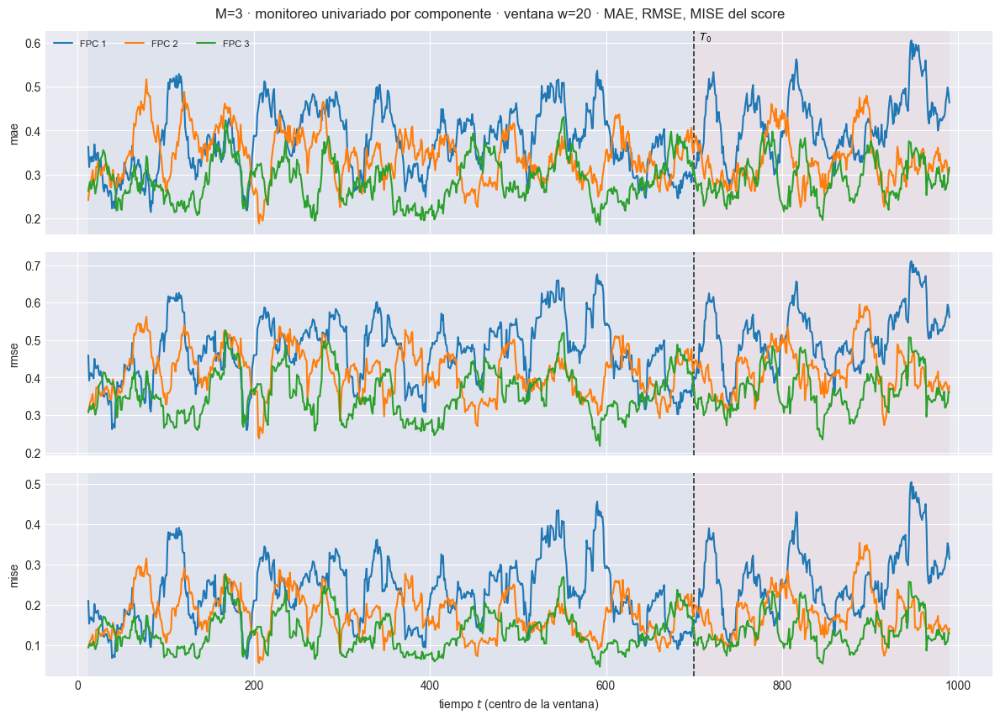

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.1s  mae: w=30 train=0.33  w=30 test=0.3284
  2/3 (66.7%) t=0.1s eta=0.0s  rmse: w=30 train=0.4154  w=30 test=0.4242
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.1725  w=30 test=0.1799
[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_m03\91_ventana_univariado_w30.png


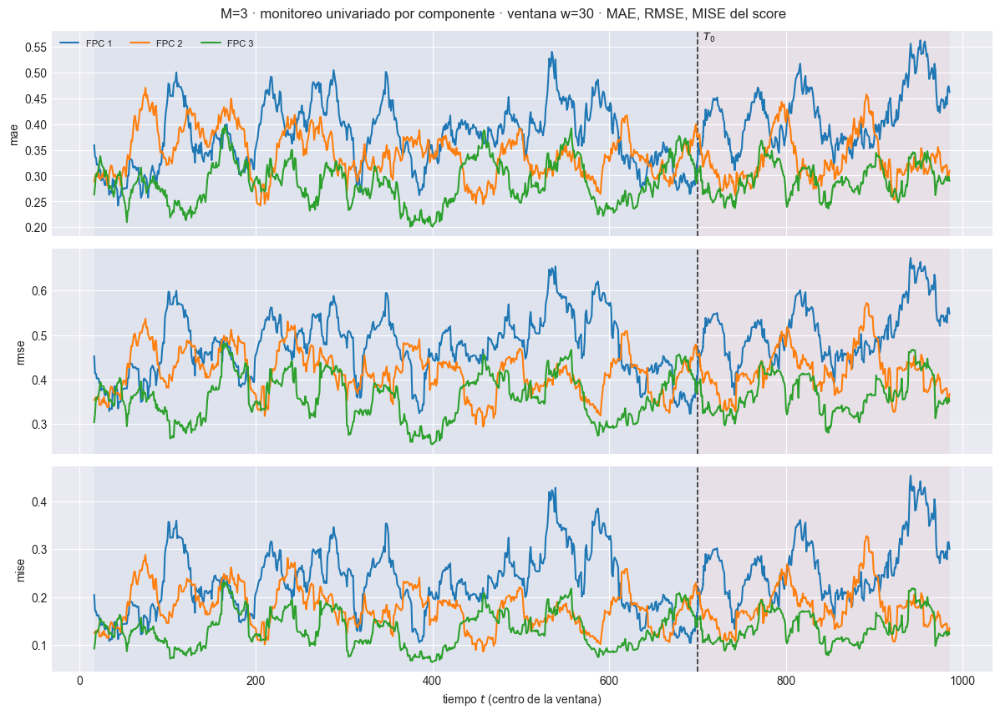

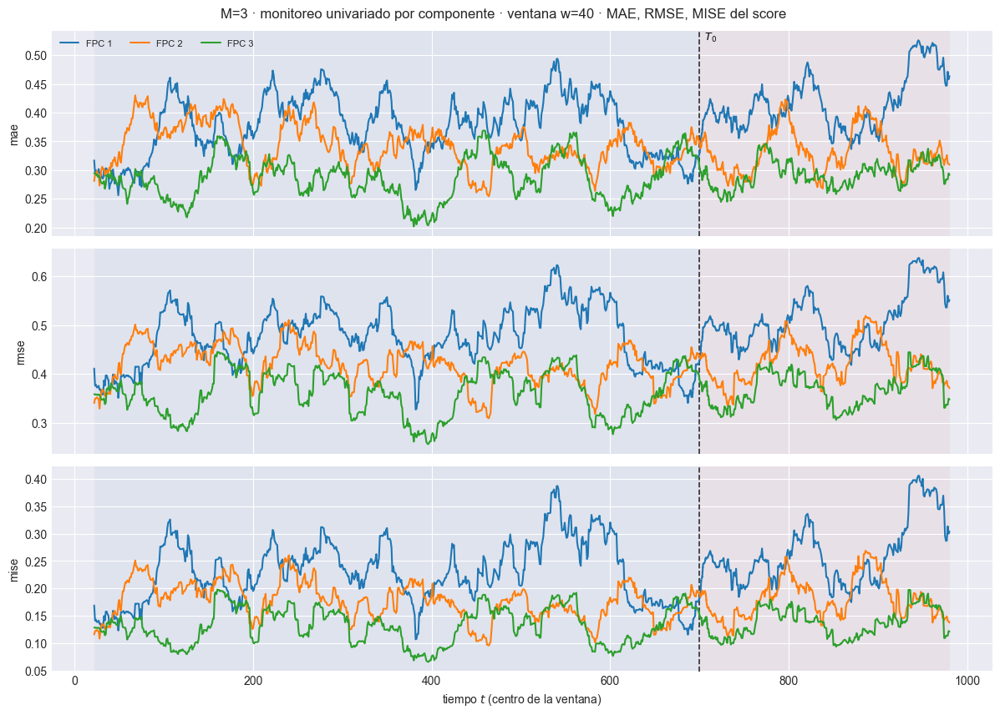

[ventana_movil_scores[FPC 1, w=30]] inicio (969 pasos)
  1/969 ( 0.1%) t=0.0s eta=0.9s  t=17 [train] rmse=0.4462
  48/969 ( 5.0%) t=0.0s eta=0.1s  t=64 [train] rmse=0.4309
  96/969 ( 9.9%) t=0.0s eta=0.1s  t=112 [train] rmse=0.5679
  144/969 (14.9%) t=0.0s eta=0.1s  t=160 [train] rmse=0.462
  192/969 (19.8%) t=0.0s eta=0.1s  t=208 [train] rmse=0.5218
  240/969 (24.8%) t=0.0s eta=0.1s  t=256 [train] rmse=0.4809
  288/969 (29.7%) t=0.0s eta=0.1s  t=304 [train] rmse=0.5007
  336/969 (34.7%) t=0.0s eta=0.1s  t=352 [train] rmse=0.5264
  384/969 (39.6%) t=0.0s eta=0.1s  t=400 [train] rmse=0.45
  432/969 (44.6%) t=0.1s eta=0.1s  t=448 [train] rmse=0.4531
  480/969 (49.5%) t=0.1s eta=0.1s  t=496 [train] rmse=0.4915
  528/969 (54.5%) t=0.1s eta=0.1s  t=544 [train] rmse=0.5855
  576/969 (59.4%) t=0.1s eta=0.0s  t=592 [train] rmse=0.5839
  624/969 (64.4%) t=0.1s eta=0.0s  t=640 [train] rmse=0.3715
  672/969 (69.3%) t=0.1s eta=0.0s  t=688 [train] rmse=0.3521
  720/969 (74.3%) t=0.1s eta=0.0s  t=73

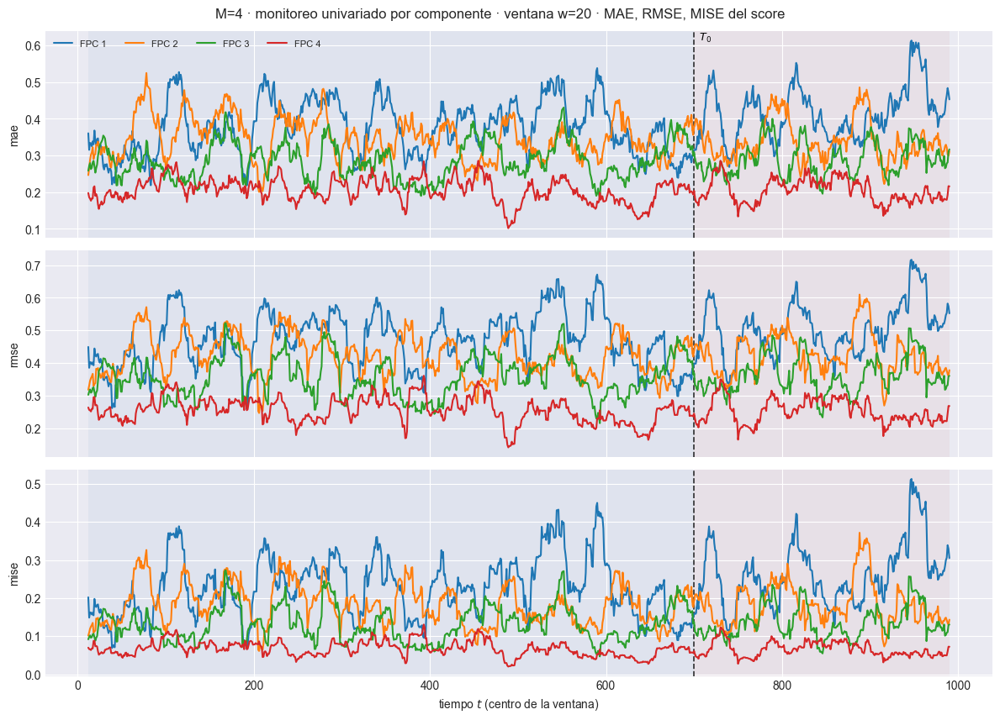

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.3042  w=30 test=0.311
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.3836  w=30 test=0.3978
  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.1472  w=30 test=0.1582
[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_m04\91_ventana_univariado_w30.png


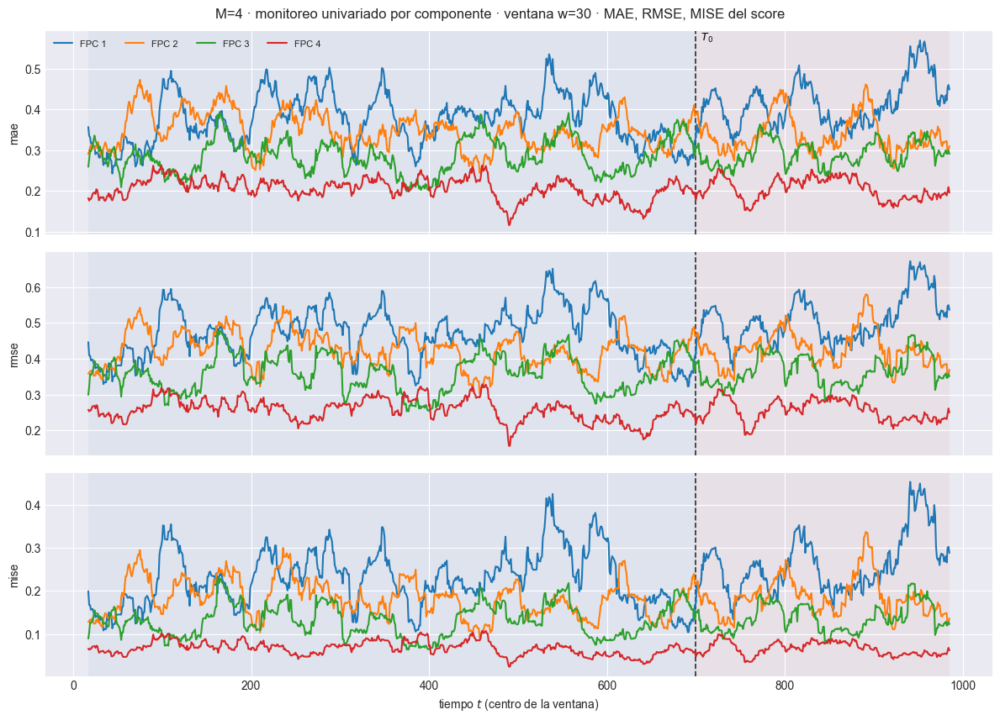

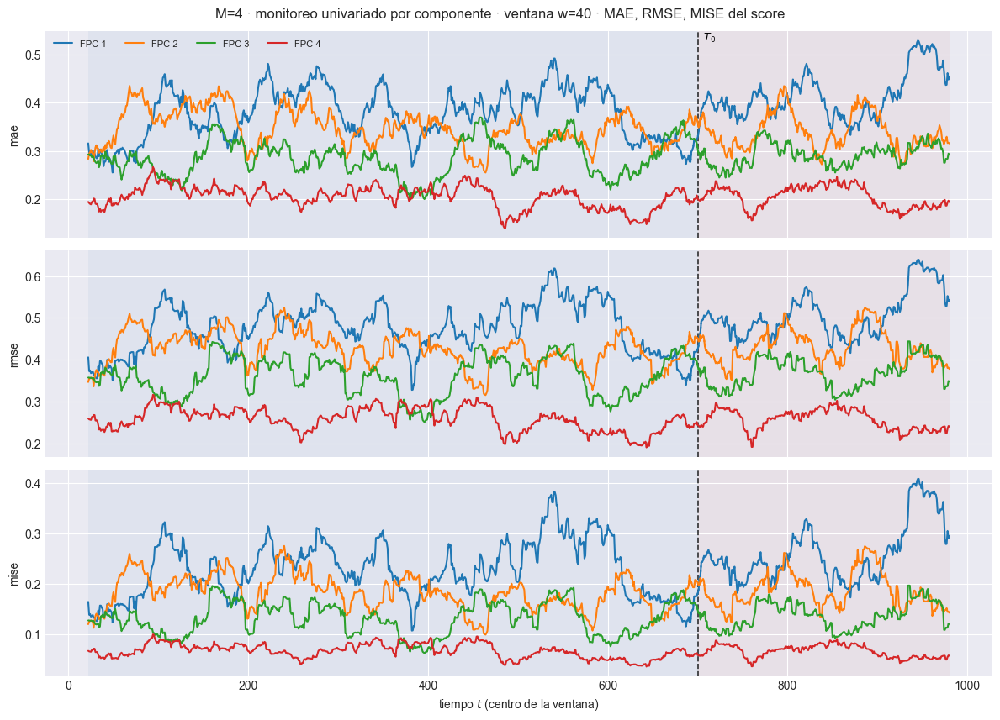

[ventana_movil_scores[FPC 1, w=30]] inicio (969 pasos)
  1/969 ( 0.1%) t=0.0s eta=1.0s  t=17 [train] rmse=0.4462
  48/969 ( 5.0%) t=0.0s eta=0.1s  t=64 [train] rmse=0.4298
  96/969 ( 9.9%) t=0.0s eta=0.1s  t=112 [train] rmse=0.5689
  144/969 (14.9%) t=0.0s eta=0.1s  t=160 [train] rmse=0.4616
  192/969 (19.8%) t=0.0s eta=0.1s  t=208 [train] rmse=0.5214
  240/969 (24.8%) t=0.0s eta=0.1s  t=256 [train] rmse=0.4809
  288/969 (29.7%) t=0.0s eta=0.1s  t=304 [train] rmse=0.5017
  336/969 (34.7%) t=0.0s eta=0.1s  t=352 [train] rmse=0.5273
  384/969 (39.6%) t=0.0s eta=0.1s  t=400 [train] rmse=0.4498
  432/969 (44.6%) t=0.0s eta=0.1s  t=448 [train] rmse=0.4535
  480/969 (49.5%) t=0.0s eta=0.0s  t=496 [train] rmse=0.492
  528/969 (54.5%) t=0.1s eta=0.0s  t=544 [train] rmse=0.5875
  576/969 (59.4%) t=0.1s eta=0.0s  t=592 [train] rmse=0.5849
  624/969 (64.4%) t=0.1s eta=0.0s  t=640 [train] rmse=0.3715
  672/969 (69.3%) t=0.1s eta=0.0s  t=688 [train] rmse=0.3522
  720/969 (74.3%) t=0.1s eta=0.0s  t=

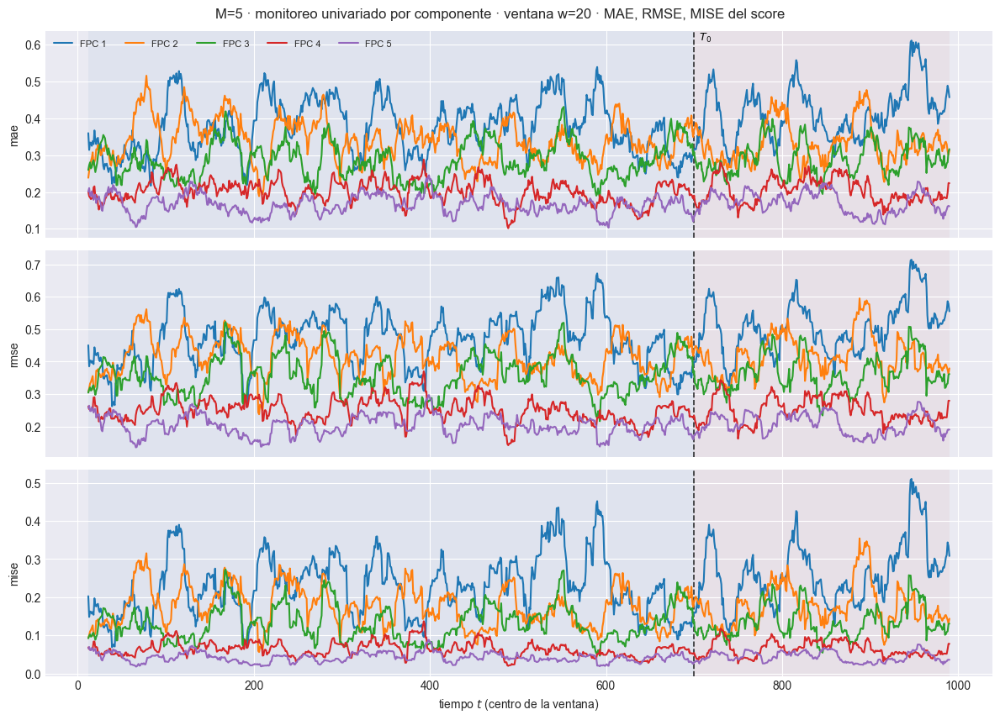

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.273  w=30 test=0.2823
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.3441  w=30 test=0.3527
  3/3 (100.0%) t=0.0s eta=0.0s  mise: w=30 train=0.1184  w=30 test=0.1244
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_m05\91_ventana_univariado_w30.png


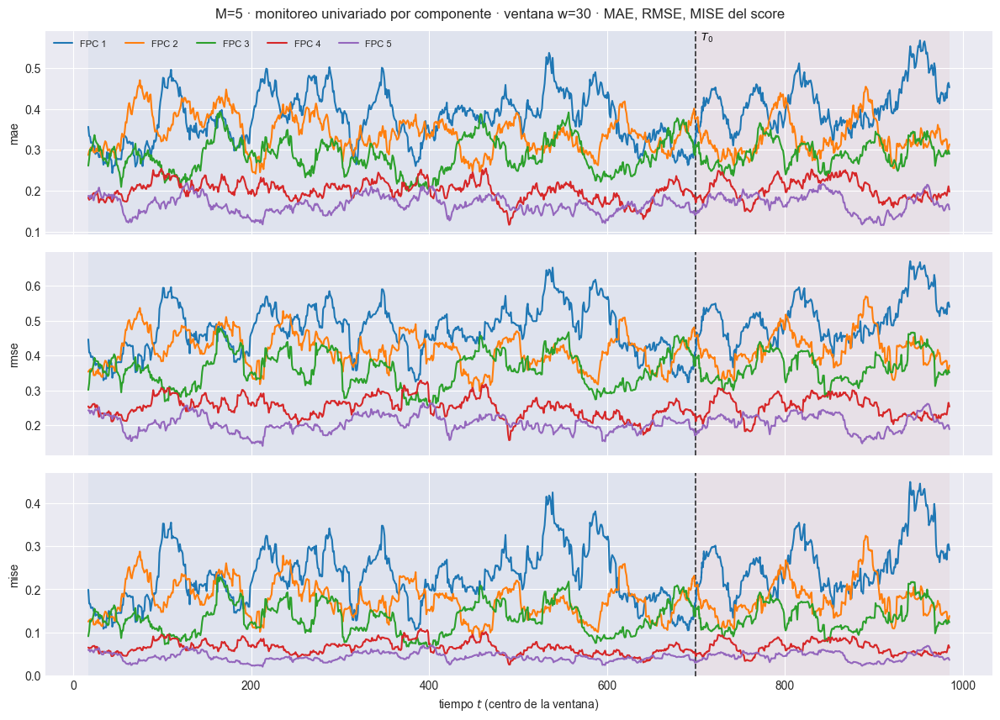

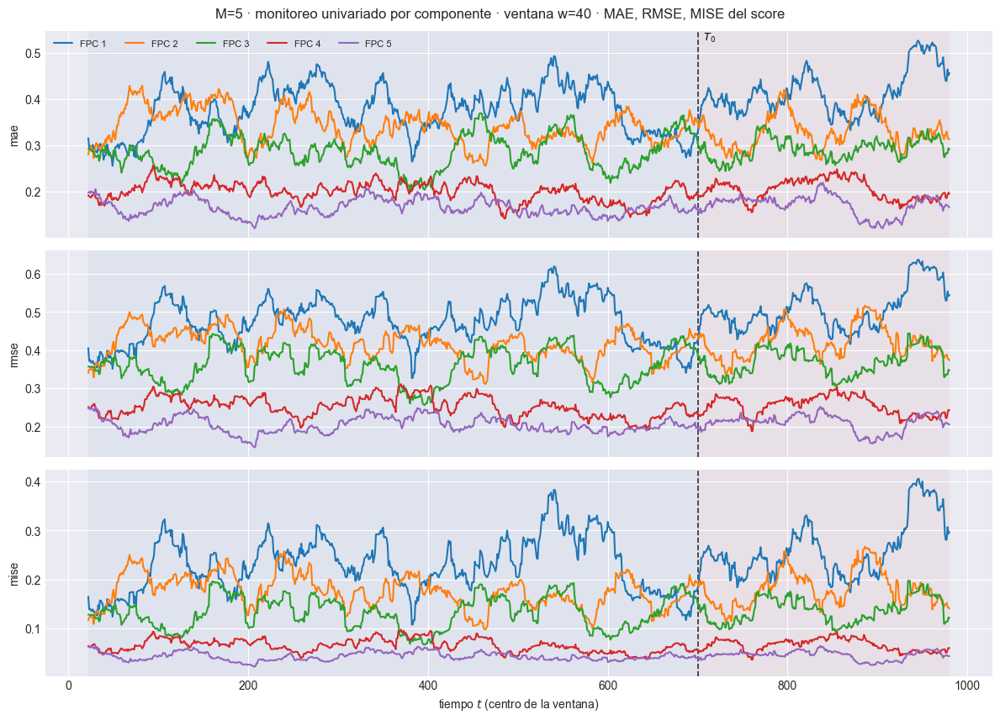

[ventana_movil_scores[FPC 1, w=30]] inicio (969 pasos)
  1/969 ( 0.1%) t=0.0s eta=1.1s  t=17 [train] rmse=0.4494
  48/969 ( 5.0%) t=0.0s eta=0.1s  t=64 [train] rmse=0.4284
  96/969 ( 9.9%) t=0.0s eta=0.1s  t=112 [train] rmse=0.572
  144/969 (14.9%) t=0.0s eta=0.1s  t=160 [train] rmse=0.4613
  192/969 (19.8%) t=0.0s eta=0.1s  t=208 [train] rmse=0.518
  240/969 (24.8%) t=0.0s eta=0.1s  t=256 [train] rmse=0.4808
  288/969 (29.7%) t=0.0s eta=0.1s  t=304 [train] rmse=0.5024
  336/969 (34.7%) t=0.0s eta=0.1s  t=352 [train] rmse=0.5282
  384/969 (39.6%) t=0.0s eta=0.1s  t=400 [train] rmse=0.4487
  432/969 (44.6%) t=0.0s eta=0.1s  t=448 [train] rmse=0.4543
  480/969 (49.5%) t=0.0s eta=0.0s  t=496 [train] rmse=0.4932
  528/969 (54.5%) t=0.1s eta=0.0s  t=544 [train] rmse=0.5885
  576/969 (59.4%) t=0.1s eta=0.0s  t=592 [train] rmse=0.5862
  624/969 (64.4%) t=0.1s eta=0.0s  t=640 [train] rmse=0.3691
  672/969 (69.3%) t=0.1s eta=0.0s  t=688 [train] rmse=0.3518
  720/969 (74.3%) t=0.1s eta=0.0s  t=7

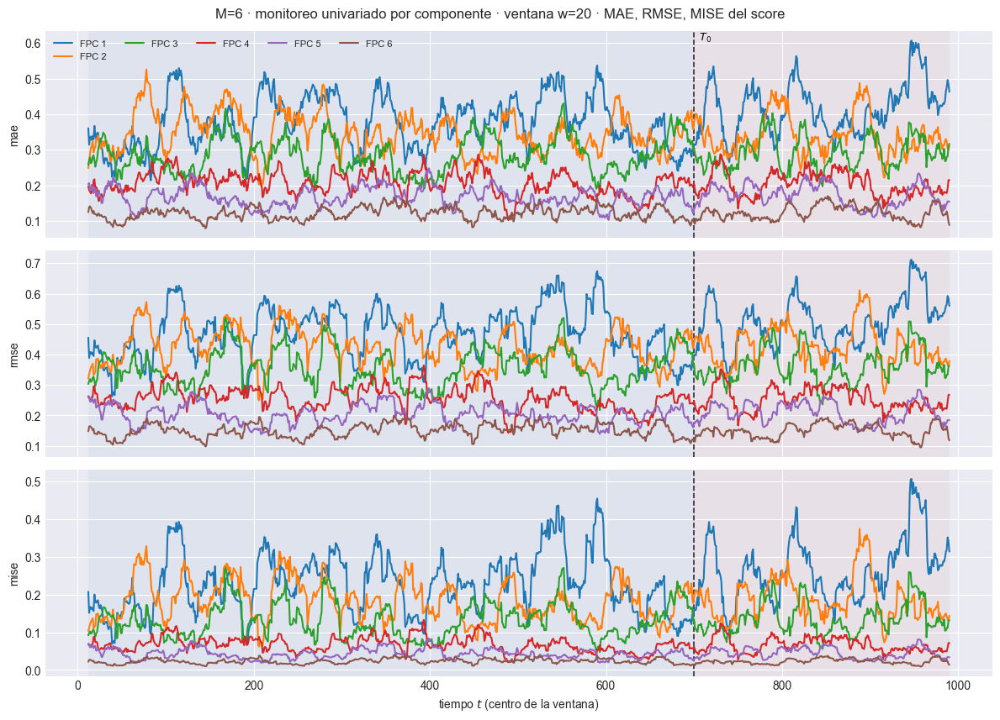

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  mae: w=30 train=0.2339  w=30 test=0.2448
  2/3 (66.7%) t=0.0s eta=0.0s  rmse: w=30 train=0.2953  w=30 test=0.3006
  3/3 (100.0%) t=0.1s eta=0.0s  mise: w=30 train=0.08718  w=30 test=0.09035
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_m06\91_ventana_univariado_w30.png


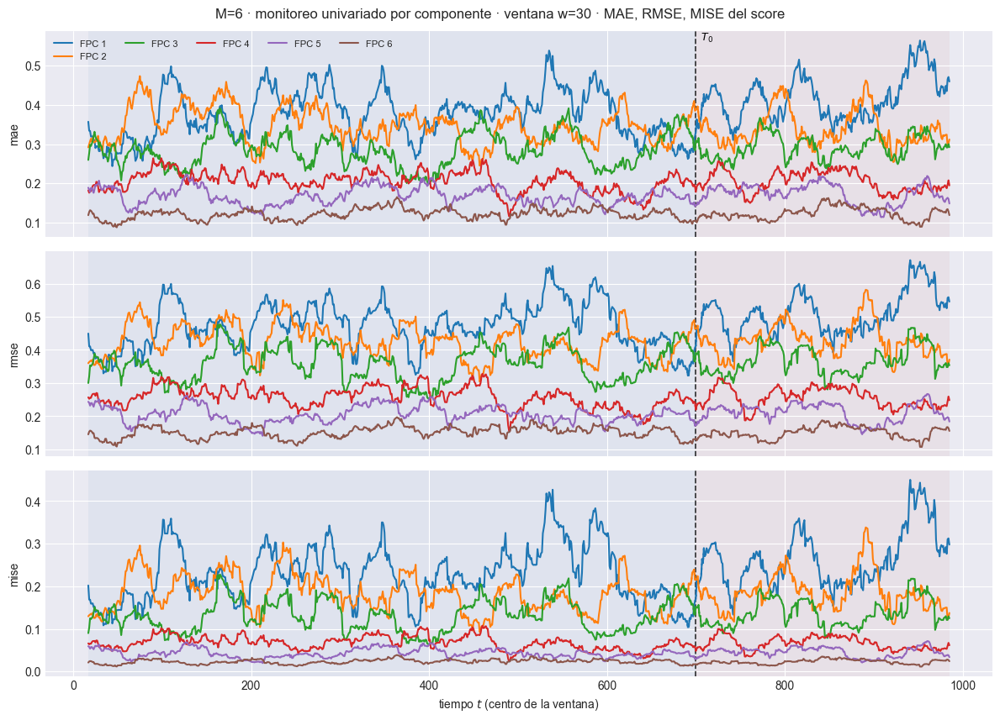

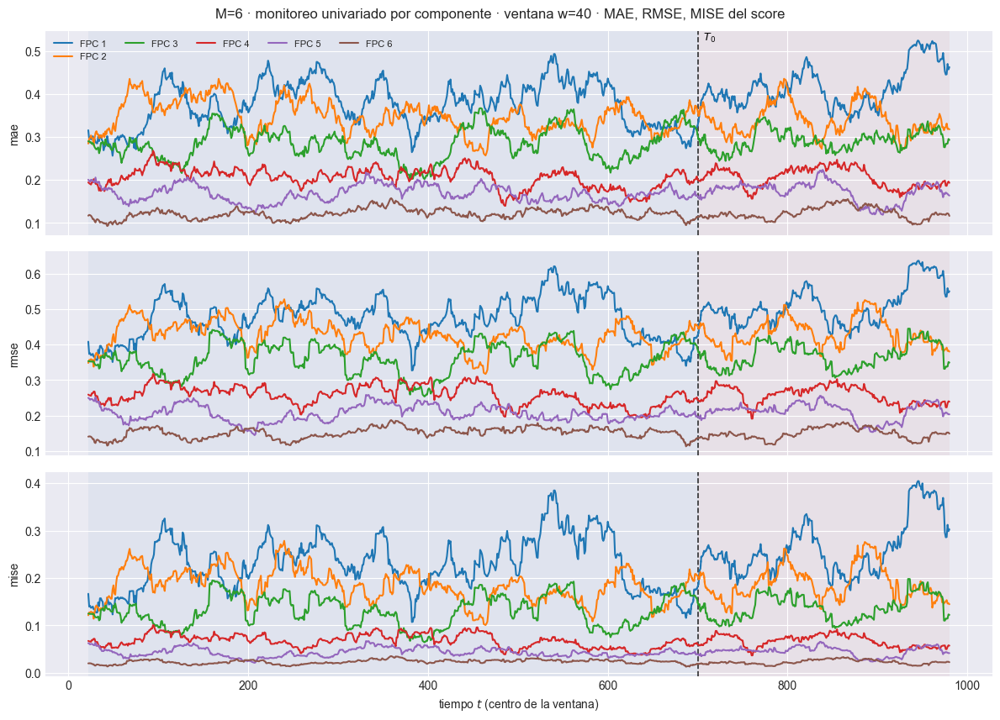

In [16]:
for M in M_OK:
    e = EST[M]
    monitoreo_scores(e, DIS, ORIG)
    for w in VENTANAS_W:
        tsc = e["tablas_score"][w].copy()
        tsc["mise"] = tsc["rmse"] ** 2      # MSE del score: análogo puntual del MISE
        plot_ventana_movil(
            tsc, T0, ["mae", "rmse", "mise"], columna_grupo="componente",
            title=f"M={M} · monitoreo univariado por componente · ventana w={w} · MAE, RMSE, MISE del score",
            save_path=str(e["paths"]["out_report"] / f"91_ventana_univariado_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

## 10. Evaluación puntual de los scores (coeficientes FPCA)

Las secciones anteriores miran la **curva**, que es el producto final. Ésta
mira el objeto que el muestreador predice de verdad: el score $\xi_{t,k}$ de
cada componente. La curva sale de propagarlos, así que un problema de
calibración que aquí se vea localizado en una componente queda, allá,
promediado con las demás y es mucho más difícil de atribuir.

| | qué muestra |
|---|---|
| **§10.1** | el intervalo de credibilidad de cada $\xi_k$ a lo largo del tiempo, con $\xi$ observado encima |
| **§10.2** | las métricas de ese intervalo: PICP, MPIW, Winkler, ACE — globales por bloque y sobre la ventana móvil, un panel por ancho |
| **§10.3** | dispersión $\hat\xi$ contra $\xi$ con la diagonal, componente a componente |

La banda es `li_s`/`ls_s`, los cuantiles muestrales de la predictiva por score
que §3 ya calculó: es **la misma** de la que sale la banda funcional, antes de
propagarla. No se vuelve a muestrear nada.


### 10.1 Cómo se mueve el intervalo de credibilidad de cada score

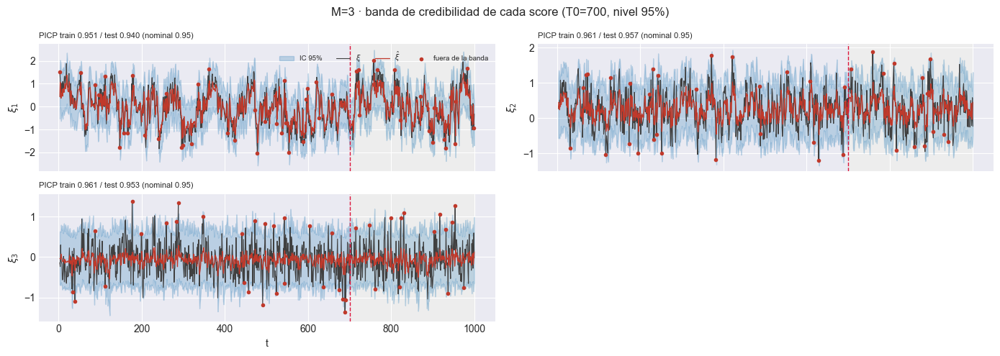

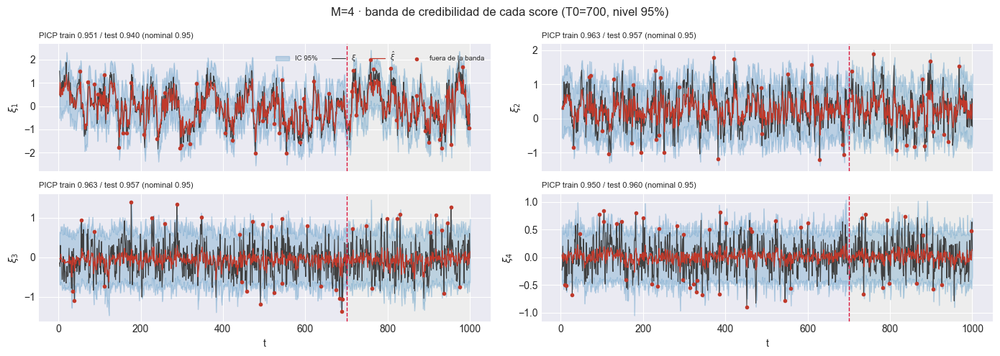

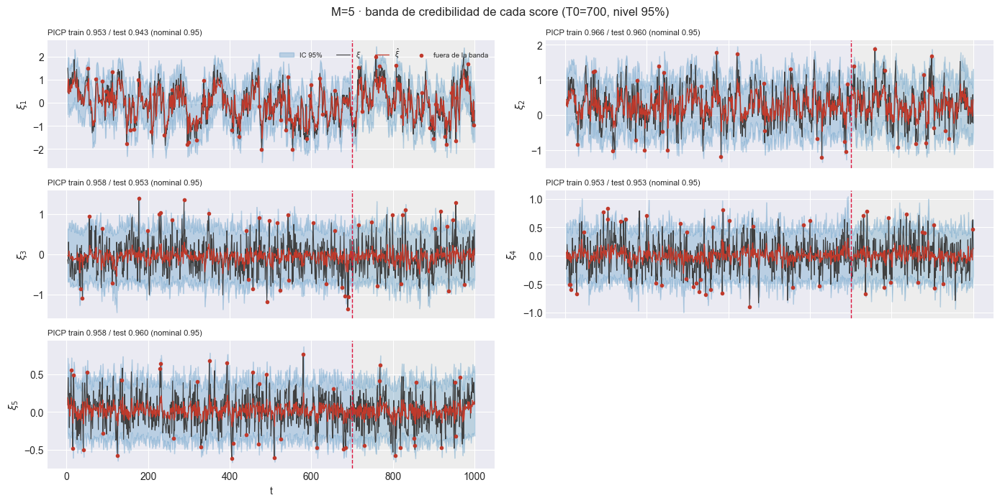

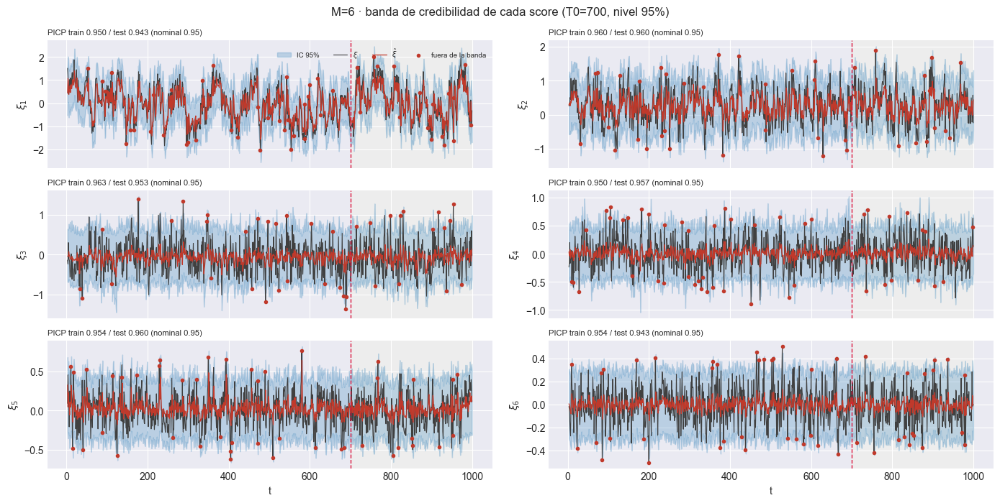

In [17]:
for M in M_OK:
    plot_scores_banda(EST[M], ORIG, DIS, M,
                      save_path=EST[M]["paths"]["out_report"] / "92_scores_banda_credibilidad.png")
    plt.show()

### 10.2 Métricas de intervalo sobre los scores

Las mismas cuatro cifras del Bloque B, pero por componente y en la escala del
score: **PICP** (fracción de orígenes cubiertos), **MPIW** (ancho medio),
**Winkler** (regla de puntuación que penaliza ancho y fallo a la vez) y
**ACE** = PICP − nominal, que es el signo de la miscalibración: negativo es
subcobertura.

Primero la lectura global por bloque; después la evolución sobre la ventana
móvil, **un panel por ancho**, con el mismo criterio de §4 y §5.


OK ninguna componente se aleja mas de 0.1 del nominal en test.


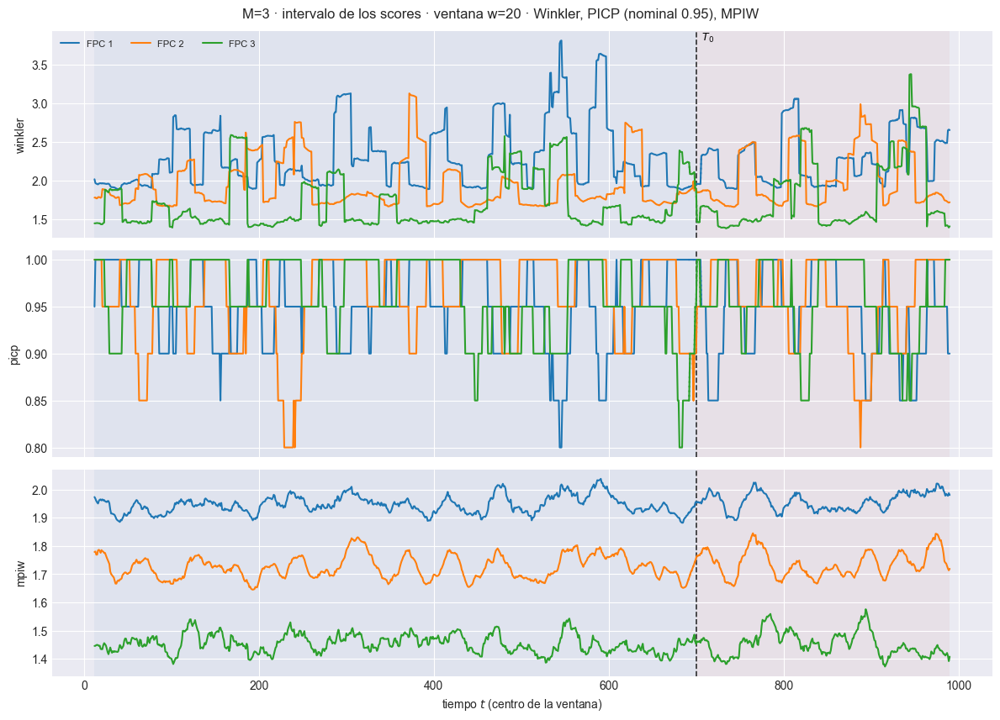

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.939  w=30 test=2.117
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.722  w=30 test=1.726
[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_m03\93_ventana_scores_intervalo_w30.png


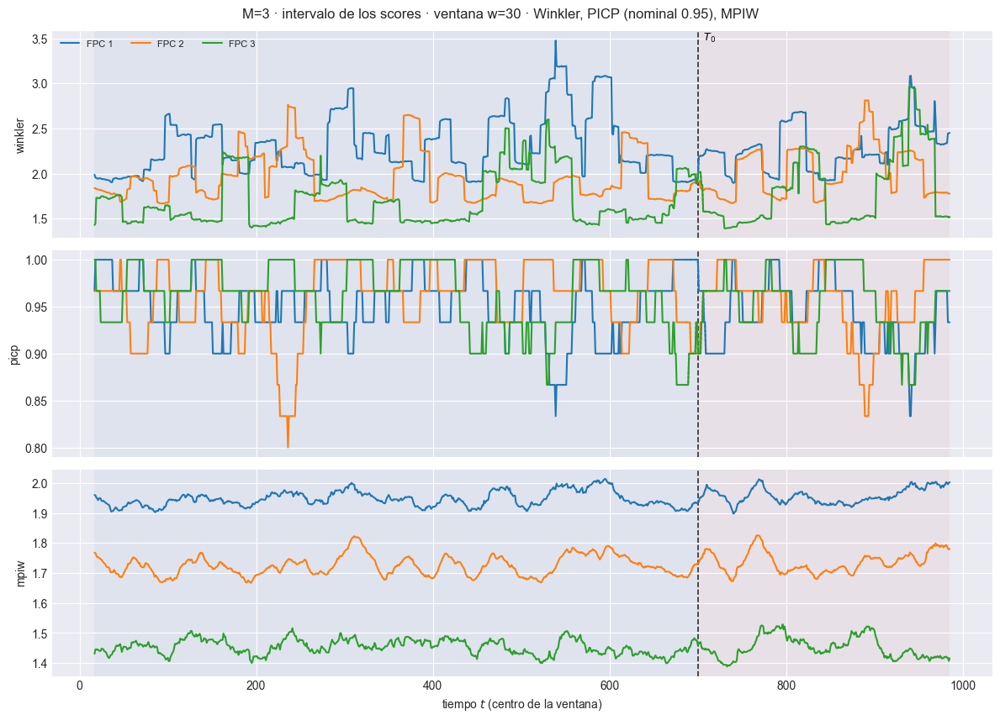

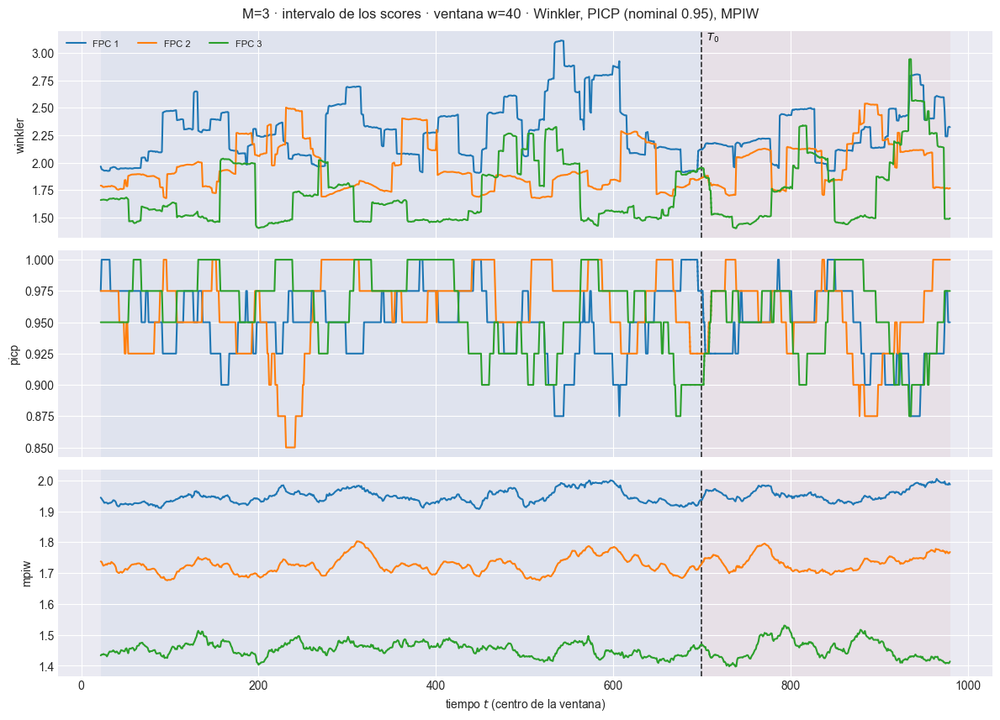

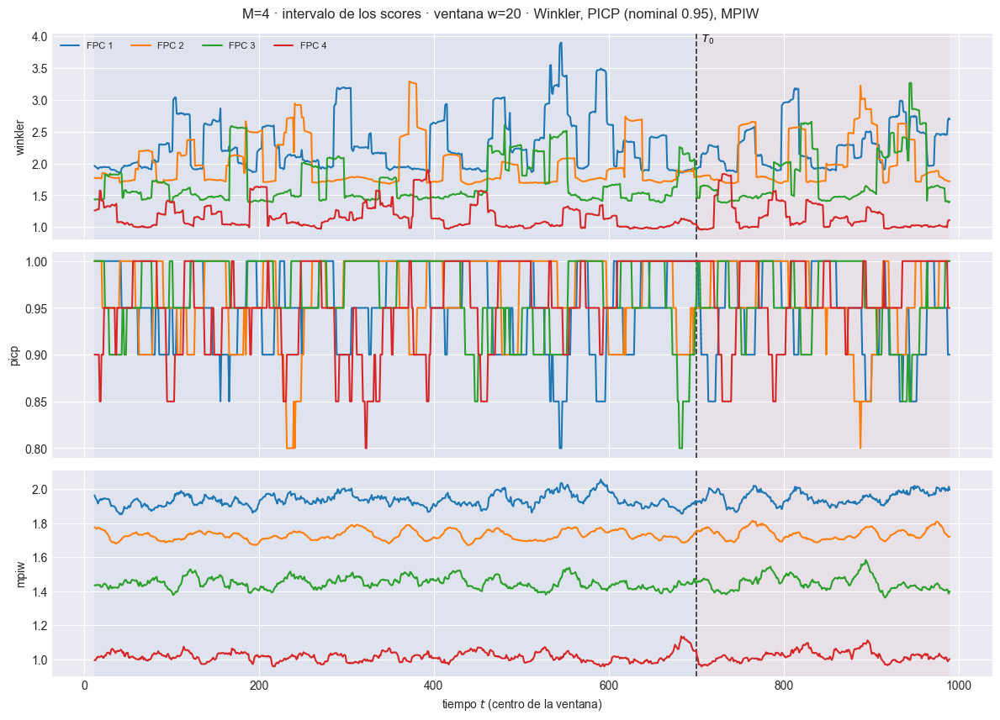

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.746  w=30 test=1.872
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.0s eta=0.0s  mpiw: w=30 train=1.595  w=30 test=1.611
[plot_ventana_movil] listo: 3 pasos en 0.3s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_m04\93_ventana_scores_intervalo_w30.png


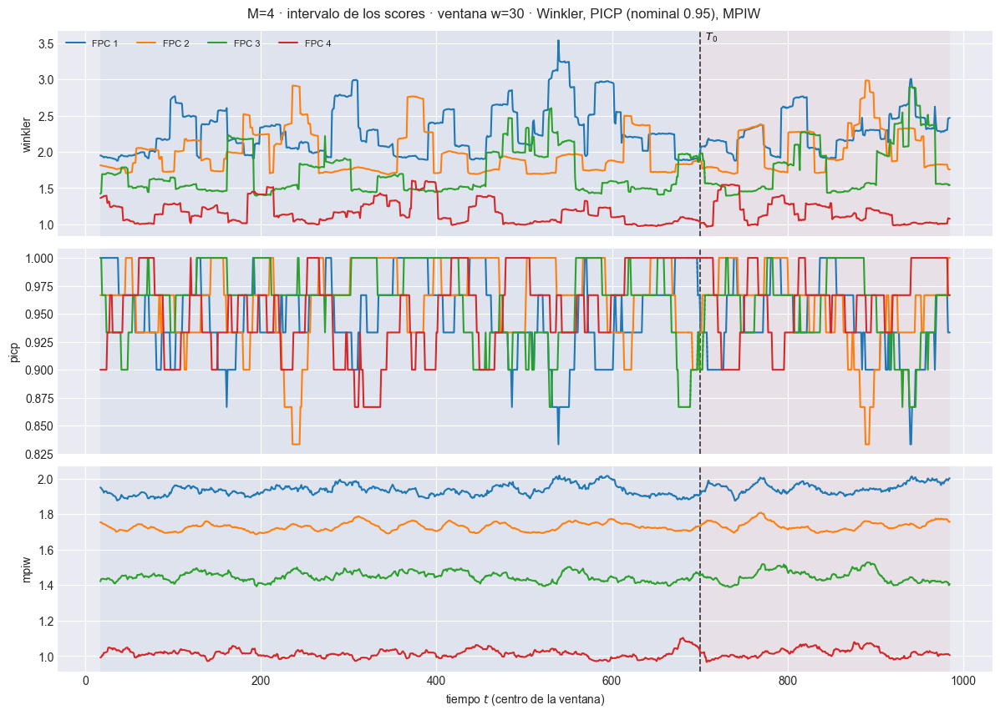

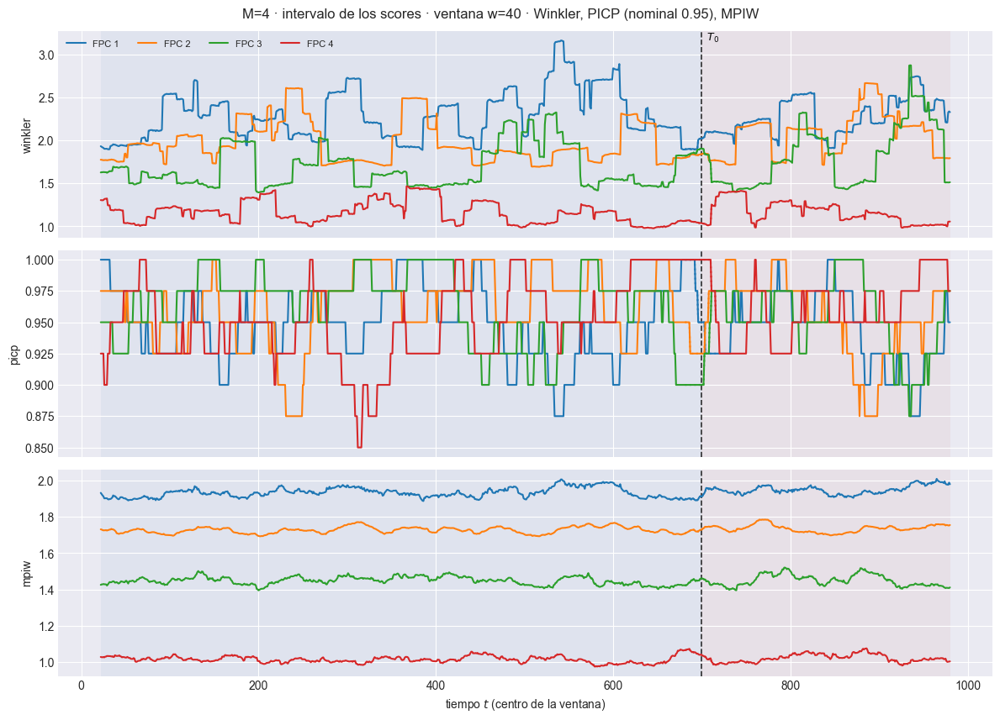

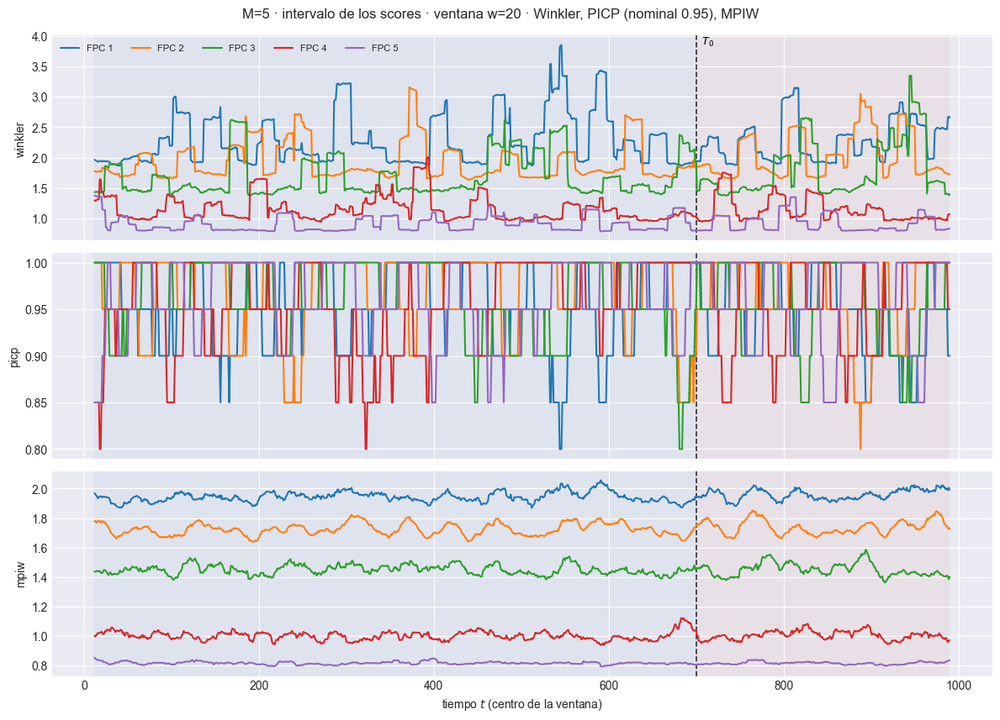

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.593  w=30 test=1.594
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.45  w=30 test=1.444
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_m05\93_ventana_scores_intervalo_w30.png


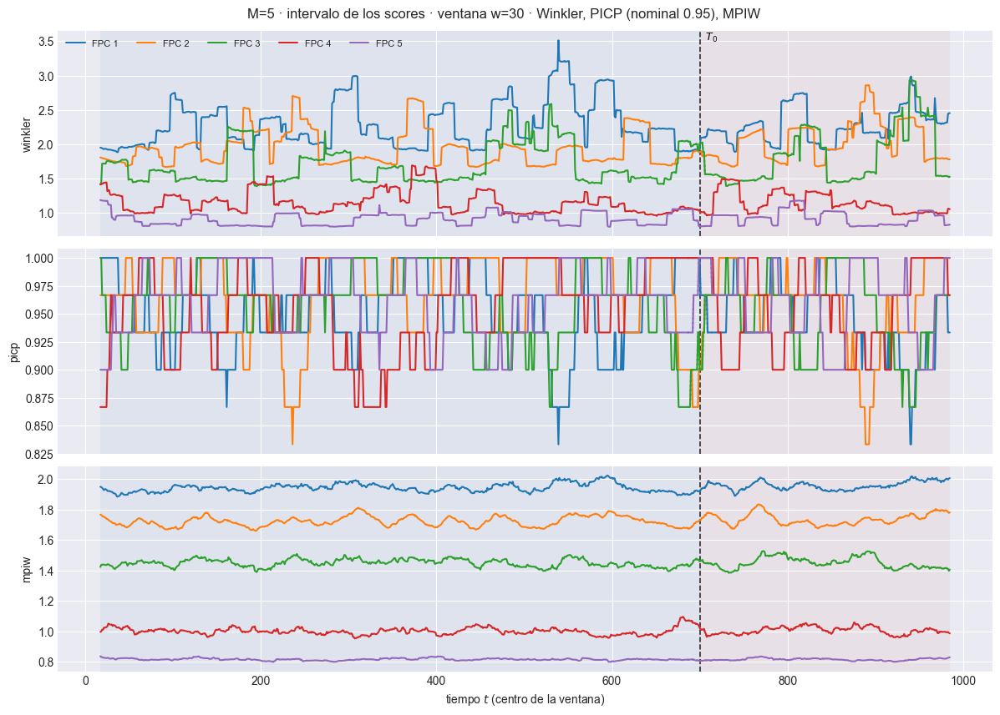

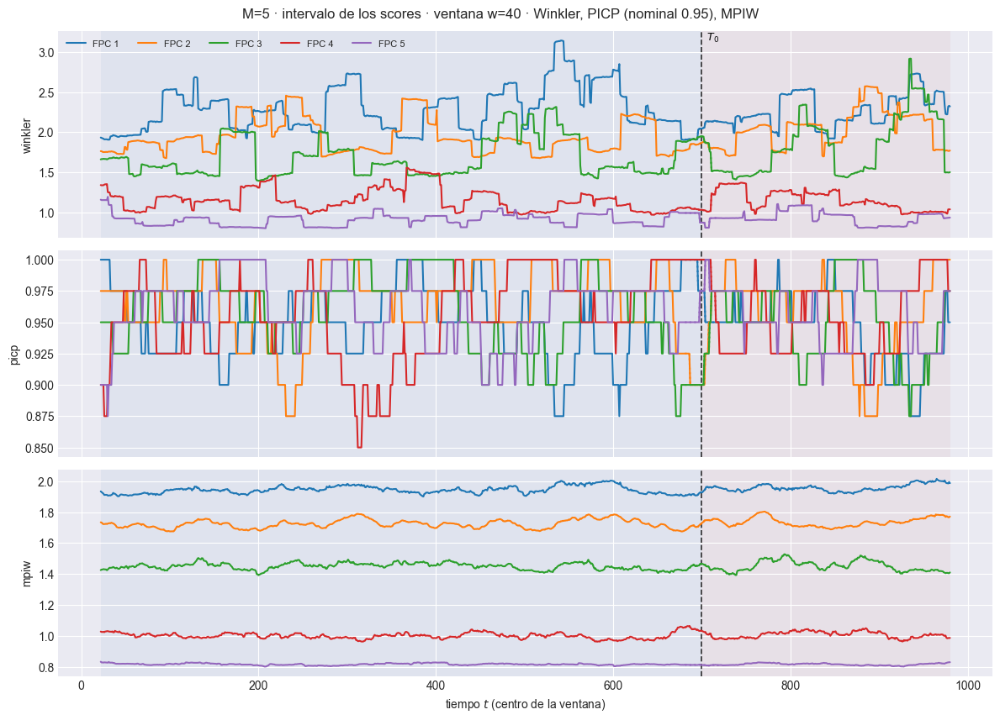

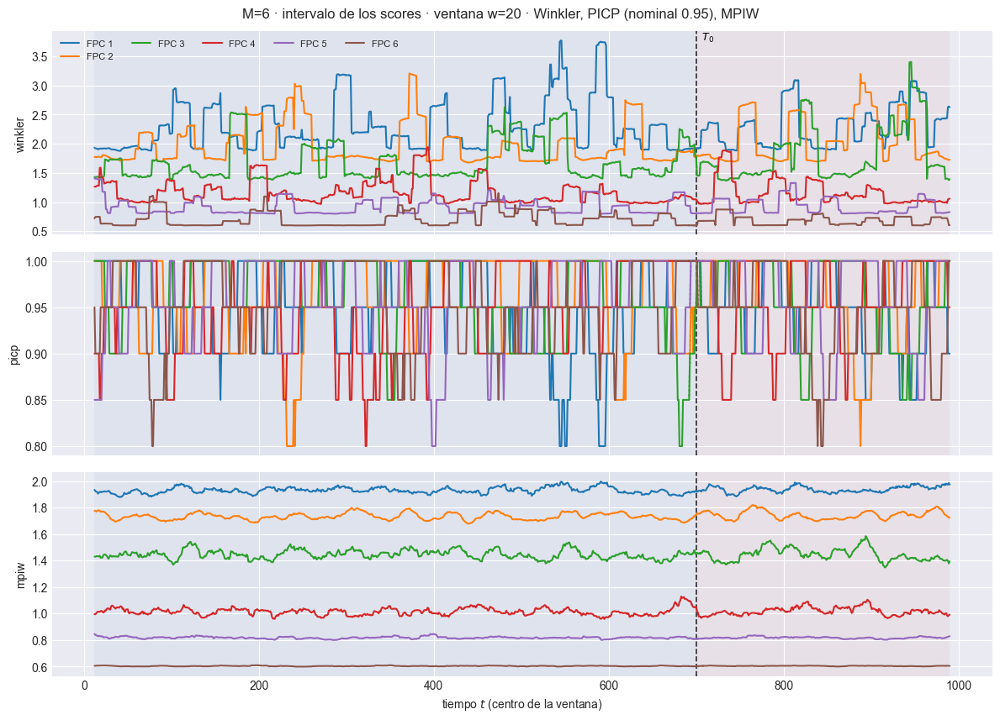

[plot_ventana_movil] inicio (3 pasos)
  1/3 (33.3%) t=0.0s eta=0.0s  winkler: w=30 train=1.436  w=30 test=1.448
  2/3 (66.7%) t=0.0s eta=0.0s  picp: w=30 train=0.9667  w=30 test=0.9667
  3/3 (100.0%) t=0.1s eta=0.0s  mpiw: w=30 train=1.247  w=30 test=1.225
[plot_ventana_movil] listo: 3 pasos en 0.4s  -> C:\Users\56jua\Desktop\git_tesis\bayesian_non_parametrics-1\reports\simulaciones\escenario_202_chungEscX_1_r01_m06\93_ventana_scores_intervalo_w30.png


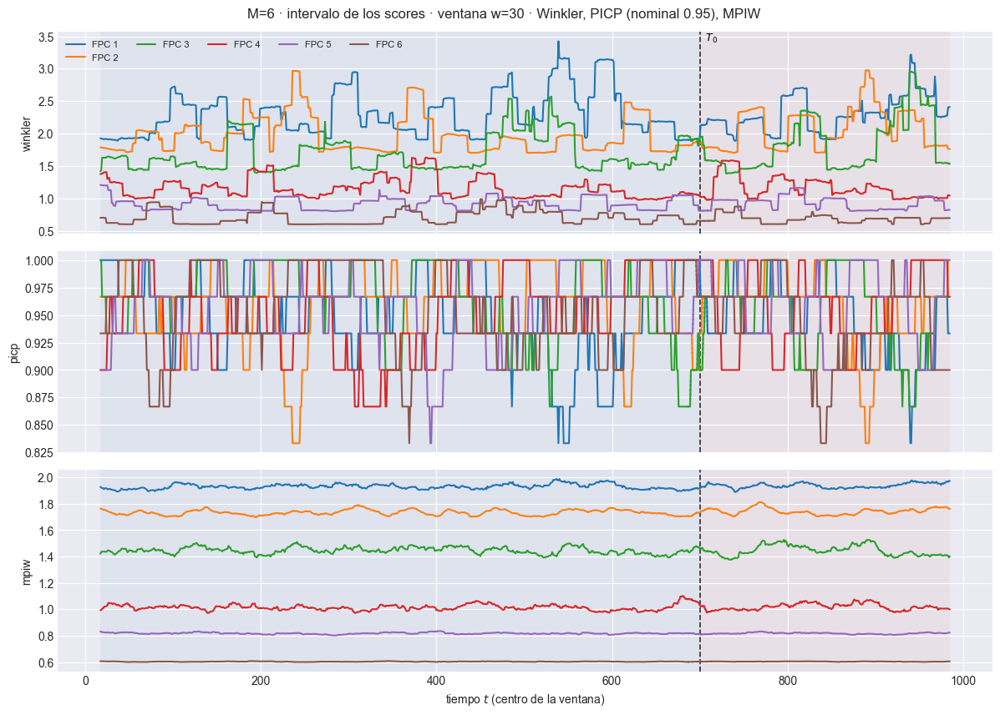

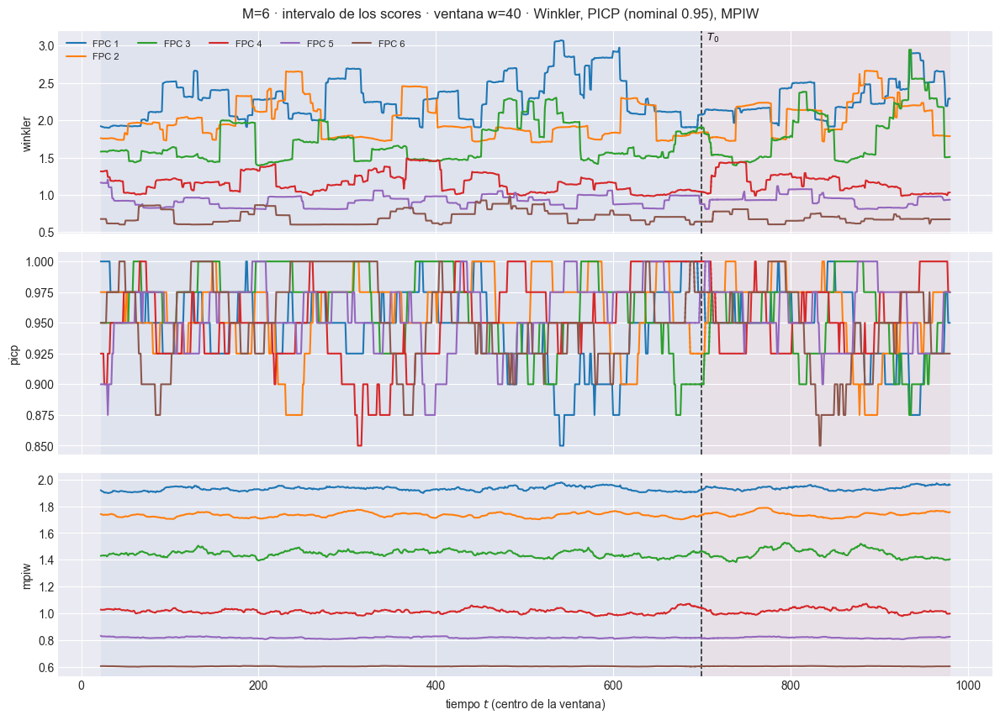

In [18]:
INT_SCORES = intervalos_scores(EST, M_OK, DIS, ORIG, PATH_BARRIDO)
display(INT_SCORES.set_index(["M", "componente", "bloque"]).style
        .format({"picp": "{:.4f}", "ace": "{:+.4f}", "mpiw": "{:.4f}", "winkler": "{:.4f}",
                 "sd_banda": "{:.4f}", "rmse": "{:.4f}", "mpiw_sobre_rmse": "{:.2f}"})
        .background_gradient(subset=["ace"], cmap="RdYlGn", vmin=-0.5, vmax=0.5)
        .set_caption(f"Intervalos de credibilidad de los scores, nivel {NIVEL:.0%} · ACE = PICP - nominal · "
                     "mpiw/rmse ≈ 3.92 si la banda fuera gaussiana y calibrada"))

# Evolución del intervalo sobre la ventana móvil, una figura por ancho.
for M in M_OK:
    for w in VENTANAS_W:
        plot_ventana_movil(
            EST[M]["tablas_score"][w], T0, ["winkler", "picp", "mpiw"], columna_grupo="componente",
            title=f"M={M} · intervalo de los scores · ventana w={w} · Winkler, PICP (nominal {NIVEL:.2f}), MPIW",
            save_path=str(EST[M]["paths"]["out_report"] / f"93_ventana_scores_intervalo_w{w}.png"),
            verbose=(w == W_REF))
        plt.show()

### 10.3 Dispersión $\hat\xi$ contra $\xi$

Un panel por componente, con la diagonal $y=x$. Tres cosas se leen de golpe:

- **la nube pegada a la diagonal** es predicción; la nube **horizontal**
  —$\hat\xi$ casi constante mientras $\xi$ varía— es el modelo prediciendo la
  media incondicional, que es lo que pasa cuando la componente no tiene
  dinámica que capturar;
- **la pendiente** de la recta ajustada: menor que 1 es encogimiento hacia la
  media, que es el comportamiento esperado de un predictor bayesiano y no un
  defecto;
- **las barras** son el intervalo de credibilidad de una submuestra, de modo
  que se ve si los puntos que se salen de la diagonal están cubiertos.

Los puntos de train y de test van con marcador distinto: si la nube de test se
descuelga de la diagonal mientras la de train no, es deriva del bloque de
prueba y no error de ajuste.


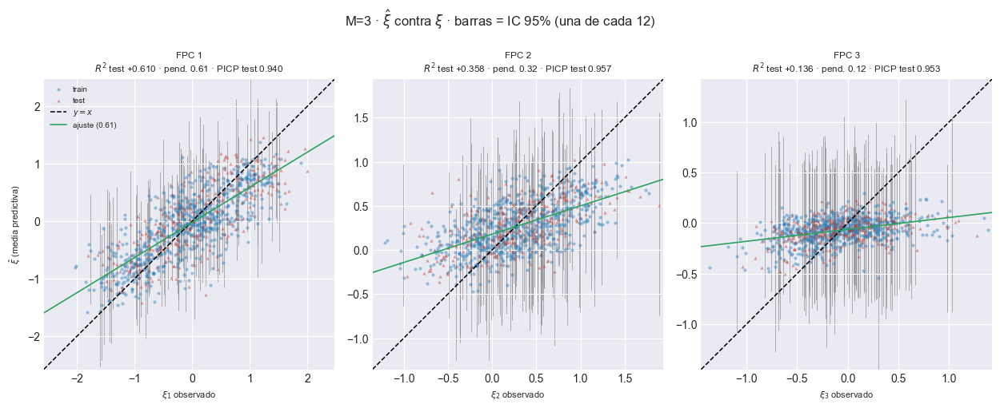

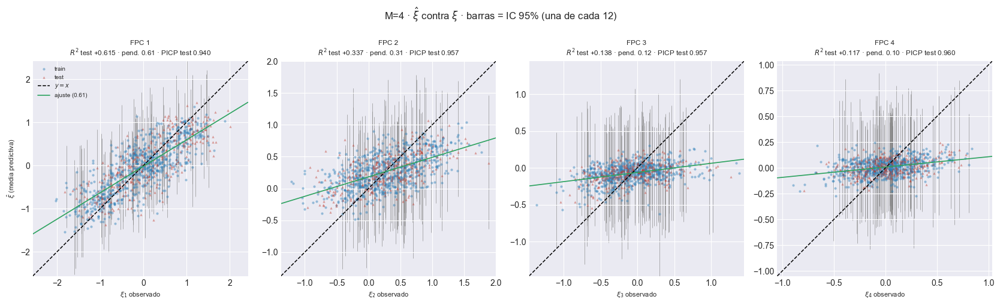

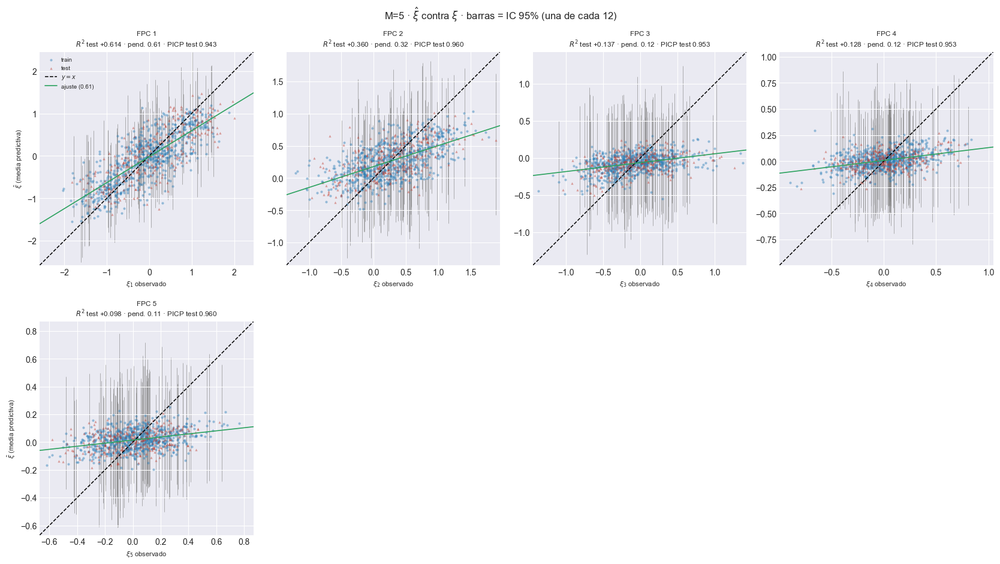

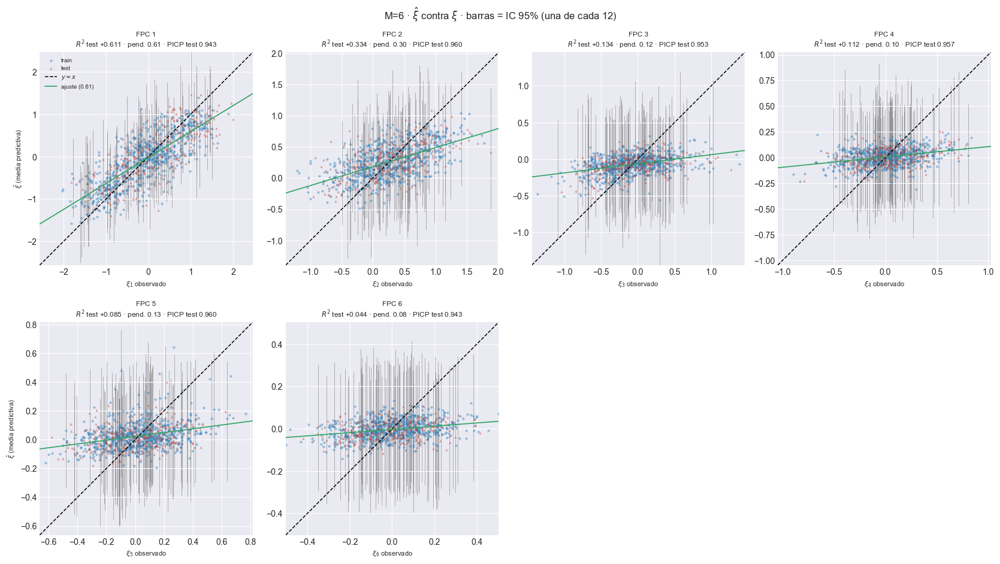

In [19]:
for M in M_OK:
    plot_scores_dispersion(EST[M], ORIG, DIS, M, CADA_BARRA,
                           save_path=EST[M]["paths"]["out_report"] / "94_scores_dispersion_vs_real.png")
    plt.show()